# Detecção de anomalias em correia transportadora — frequências variadas

Detecção não supervisionada de anomalias em sinais de acelerômetro e giroscópio coletados a **100 Hz, 200 Hz e 500 Hz**.


As coletas são organizadas por frequência, tipo de anomalia e trecho da correia.

- **`alinhado`**: condição considerada normal e usada para treinar o modelo e calcular os limiares locais.
- **`bloco`**: anomalia produzida por um bloco de madeira colocado na estrutura da correia para gerar picos anômalos.
- **`ext`**: anomalia provocada manualmente em um local repetível da correia.
- **`an_0_1`, `an_1_2`, ..., `an_4_0`**: o sufixo identifica o trecho entre marcos consecutivos definidos durante a coleta. Há uma imagem da correia com essa numeração no repositório.

Os arquivos removidos foram selecionados via inspeção manual. Foram excluídas coletas sem a passagem completa pela parte superior da correia e coletas muito diferentes das demais sem uma causa experimental identificada.

## Fluxo do processamento

Carregamento → seleção das coletas → alinhamento de posição → janelas e features → padronização/PCA/K-Means → limiares locais → detecção e pós-processamento.


## Dependências e ambiente


In [1]:
# %pip install dtaidistance

import os
import glob
import math
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import scipy.signal
import scipy.fft
import joblib

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 160)
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 240)
pd.set_option('display.max_rows', 300)

try:
    from dtaidistance import dtw
    TEM_DTAIDISTANCE = True
except ImportError:
    TEM_DTAIDISTANCE = False
    print('Será usado um DTW simples em numpy')

C:\Users\Raiza\AppData\Roaming\Python\Python311\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Raiza\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## Configuração do conjunto de dados

In [2]:
RAIZ_DADOS = r"C:/Users/Raiza/OneDrive/Documentos/verlab/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/receptor/freq_variadas"

FREQUENCIAS = {
    '100Hz': 100,
    '200Hz': 200,
    '500Hz': 500,
}

TIPOS_COLETA = ['bloco', 'ext']
COLETAS_VALIDAS = {
    ('100Hz', 'bloco'),
    ('100Hz', 'ext'),
    ('200Hz', 'bloco'),
    ('200Hz', 'ext'),
    ('500Hz', 'ext'),
}
GRUPO_NORMAL = 'alinhado'
GRUPOS_ANOMALIA = ['an_0_1', 'an_1_2', 'an_2_3', 'an_3_4', 'an_4_0']
GRUPOS = [GRUPO_NORMAL] + GRUPOS_ANOMALIA

### Parâmetros de segmentação, alinhamento, modelagem e detecção


In [3]:
JANELA_SEG = 1.28
STEP_SEG = 0.32
N_PAD_FFT_BASE = 256

USAR_DTW = False
DTW_COL = 'accel_z'
DTW_PENALTY = 0.1
DTW_USAR_WINDOW = False
DTW_WINDOW = 80
BASE_IDX_NORMAL = 0

N_BINS_POSICAO = 24
LIMIAR_PERCENTIL_LOCAL = 97.5
FATOR_LIMIAR_LOCAL = 1.00
K_CLUSTERS = None
N_COMPONENTES_PCA = 0.95

### Parâmetros do pós-processamento

In [4]:
MIN_JANELAS_CONSECUTIVAS = 3
MIN_COMPRIMENTO_INTERVALO_SEG = 0.80
SCORE_MIN_INTERVALO = 1.00
MAX_GAP_ENTRE_JANELAS = 0

### Características físicas e conversões do sensor


In [5]:
RANGE_ACC_G = 4
RANGE_GYRO_DPS = 1000
CONVERSION_FACTOR_ACC_G = RANGE_ACC_G / (2**15)
CONVERSION_FACTOR_ACC = CONVERSION_FACTOR_ACC_G * 9.81
CONVERSION_FACTOR_GYRO_DPS = RANGE_GYRO_DPS / (2**15)

### Sinais utilizados e bandas de frequência

In [6]:
EIXOS_RAW = ['accel_x', 'accel_y', 'accel_z']
EIXOS_GYRO_RAW = ['gyro_x', 'gyro_y', 'gyro_z']
EIXOS_HP = ['x_acc_hp', 'y_acc_hp', 'z_acc_hp']

FEATURE_COLS = ['x_acc_hp', 'y_acc_hp', 'z_acc_hp', 'acc_hp_mag', 'angle_y_deg']

FREQ_BANDS_BASE = [
    (0.5, 2),
    (2, 5),
    (5, 10),
    (10, 20),
    (20, 40),
    (40, 80),
    (80, 160),
    (160, 240),
]

### Inspeção e exclusões manuais

Os índices reproduzem a seleção feita via inspeção visual. Dependem da lista ordenada de CSVs


In [7]:
PLOTAR_ARQUIVOS_ANTES_REMOVER = False
MAX_ARQUIVOS_POR_FIGURA_INSPECAO = 12
COLS_INSPECAO = ['accel_z', 'angle_y_deg']

INDICES_REMOVER = {
    freq: {
        tipo: {
            grupo: []
            for grupo in GRUPOS
        }
        for tipo in TIPOS_COLETA
    }
    for freq in FREQUENCIAS
}

INDICES_REMOVER['100Hz']['bloco']['alinhado'] = [7, 8]
INDICES_REMOVER['100Hz']['bloco']['an_0_1'] = [12]
INDICES_REMOVER['100Hz']['bloco']['an_3_4'] = [6]
INDICES_REMOVER['100Hz']['bloco']['an_4_0'] = [0]
INDICES_REMOVER['100Hz']['ext']['alinhado'] = [0]
INDICES_REMOVER['100Hz']['ext']['an_1_2'] = [0]
INDICES_REMOVER['100Hz']['ext']['an_3_4'] = [3]

INDICES_REMOVER['200Hz']['bloco']['alinhado'] = [6, 8]
INDICES_REMOVER['200Hz']['bloco']['an_2_3'] = [0, 1]
INDICES_REMOVER['200Hz']['ext']['alinhado'] = [16, 17, 18, 19, 25]
INDICES_REMOVER['200Hz']['ext']['an_0_1'] = [12]
INDICES_REMOVER['200Hz']['ext']['an_3_4'] = [7]
INDICES_REMOVER['200Hz']['ext']['an_4_0'] = [0, 6]

INDICES_REMOVER['500Hz']['ext']['alinhado'] = [3, 9, 12]
INDICES_REMOVER['500Hz']['ext']['an_0_1'] = [6, 17]
INDICES_REMOVER['500Hz']['ext']['an_1_2'] = [0]
INDICES_REMOVER['500Hz']['ext']['an_3_4'] = [3, 9]
INDICES_REMOVER['500Hz']['ext']['an_4_0'] = [3]

## Pré-processamento dos sinais

In [8]:
def parametros_janela(fs):
    """Converte os parâmetros temporais do experimento em tamanhos de janela, passo, comprimento mínimo e FFT para a frequência informada."""
    n_janela = max(8, int(round(JANELA_SEG * fs)))
    step = max(1, int(round(STEP_SEG * fs)))
    min_comprimento = max(step, int(round(MIN_COMPRIMENTO_INTERVALO_SEG * fs)))
    n_pad = max(N_PAD_FFT_BASE, 2 ** int(np.ceil(np.log2(n_janela))))
    return n_janela, step, min_comprimento, n_pad


def bandas_validas(fs):
    """Limita as bandas espectrais à frequência de Nyquist do conjunto analisado."""
    nyq = fs / 2
    bandas = [(f1, f2) for f1, f2 in FREQ_BANDS_BASE if f1 < nyq]
    bandas = [(f1, min(f2, nyq)) for f1, f2 in bandas if min(f2, nyq) > f1]
    return bandas


def filter_signal(data, cutoff, order, dt):
    """Aplica um filtro Butterworth passa-baixas usado para estimar a componente lenta do sinal."""
    fs = 1 / dt
    if cutoff >= fs / 2:
        cutoff = fs / 2 * 0.8
    sos = scipy.signal.butter(order, cutoff, btype='lowpass', fs=fs, output='sos')
    x = np.asarray(data, dtype=float)
    if len(x) < max(12, order * 6):
        return x - np.nanmean(x)
    return scipy.signal.sosfiltfilt(sos, x)


def zscore_np(x):
    """Centraliza e normaliza um vetor; vetores constantes são convertidos em zeros."""
    x = np.asarray(x, dtype=float)
    s = np.nanstd(x)
    if s == 0 or np.isnan(s):
        return x * 0
    return (x - np.nanmean(x)) / s

In [9]:
def madgwick_imu(acc_g, gyro_rad_s, fs, beta=0.1):
    """Estima a orientação do sensor por Madgwick usando acelerômetro e giroscópio e retorna um quaternion por amostra."""
    acc_g = np.asarray(acc_g, dtype=float)
    gyro_rad_s = np.asarray(gyro_rad_s, dtype=float)
    n = len(acc_g)
    q = np.zeros((n, 4), dtype=float)
    q[0] = np.array([1.0, 0.0, 0.0, 0.0])
    dt = 1.0 / fs

    for t in range(1, n):
        q1, q2, q3, q4 = q[t-1]
        gx, gy, gz = gyro_rad_s[t]
        ax, ay, az = acc_g[t]

        norm = math.sqrt(ax*ax + ay*ay + az*az)
        if norm > 1e-12:
            ax, ay, az = ax / norm, ay / norm, az / norm

            f = np.array([
                2*(q2*q4 - q1*q3) - ax,
                2*(q1*q2 + q3*q4) - ay,
                2*(0.5 - q2*q2 - q3*q3) - az
            ])

            J = np.array([
                [-2*q3,  2*q4, -2*q1, 2*q2],
                [ 2*q2,  2*q1,  2*q4, 2*q3],
                [ 0.0,  -4*q2, -4*q3, 0.0]
            ])

            step = J.T @ f
            step_norm = np.linalg.norm(step)
            if step_norm > 1e-12:
                step = step / step_norm
            else:
                step = np.zeros(4)
        else:
            step = np.zeros(4)

        q_dot = 0.5 * np.array([
            -q2*gx - q3*gy - q4*gz,
             q1*gx + q3*gz - q4*gy,
             q1*gy - q2*gz + q4*gx,
             q1*gz + q2*gy - q3*gx
        ]) - beta * step

        q[t] = q[t-1] + q_dot * dt
        q_norm = np.linalg.norm(q[t])
        if q_norm > 1e-12:
            q[t] /= q_norm
        else:
            q[t] = q[t-1]

    return q

In [10]:
def quat_to_euler_deg(q):
    """Converte uma sequência de quaternions em ângulos de Euler, em graus."""
    q = np.asarray(q, dtype=float)
    w, x, y, z = q[:, 0], q[:, 1], q[:, 2], q[:, 3]

    roll = np.arctan2(2*(w*x + y*z), 1 - 2*(x*x + y*y))
    pitch_arg = 2*(w*y - z*x)
    pitch_arg = np.clip(pitch_arg, -1, 1)
    pitch = np.arcsin(pitch_arg)
    yaw = np.arctan2(2*(w*z + x*y), 1 - 2*(y*y + z*z))

    return np.rad2deg(roll), np.rad2deg(pitch), np.rad2deg(yaw)


def unwrap_angle_deg(angle):
    """Remove descontinuidades de múltiplos de 360 graus de uma sequência angular."""
    return np.rad2deg(np.unwrap(np.deg2rad(np.asarray(angle, dtype=float))))


def preprocess_dataframe(df, fs):
    """
    Prepara uma coleta para as etapas de alinhamento e extração de features.
    
    Valida e interpola os sinais, converte unidades, estima a orientação por Madgwick, remove a componente lenta da aceleração e cria os eixos de amostra e tempo.
    """
    df = df.copy().reset_index(drop=True)
    faltantes = [c for c in EIXOS_RAW if c not in df.columns]
    if faltantes:
        raise ValueError(f'Colunas ausentes no CSV: {faltantes}')

    for col in EIXOS_RAW + EIXOS_GYRO_RAW:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    df[EIXOS_RAW] = df[EIXOS_RAW].interpolate().bfill().ffill()

    for col in EIXOS_GYRO_RAW:
        if col not in df.columns:
            df[col] = 0.0
    df[EIXOS_GYRO_RAW] = df[EIXOS_GYRO_RAW].interpolate().bfill().ffill()

    df['accel_x_g'] = df['accel_x'].astype(float) * CONVERSION_FACTOR_ACC_G
    df['accel_y_g'] = df['accel_y'].astype(float) * CONVERSION_FACTOR_ACC_G
    df['accel_z_g'] = df['accel_z'].astype(float) * CONVERSION_FACTOR_ACC_G

    df['accel_x_ms2'] = df['accel_x_g'] * 9.81
    df['accel_y_ms2'] = df['accel_y_g'] * 9.81
    df['accel_z_ms2'] = df['accel_z_g'] * 9.81

    df['gyro_x_dps'] = df['gyro_x'].astype(float) * CONVERSION_FACTOR_GYRO_DPS
    df['gyro_y_dps'] = df['gyro_y'].astype(float) * CONVERSION_FACTOR_GYRO_DPS
    df['gyro_z_dps'] = df['gyro_z'].astype(float) * CONVERSION_FACTOR_GYRO_DPS

    df['gyro_x_rad_s'] = np.deg2rad(df['gyro_x_dps'])
    df['gyro_y_rad_s'] = np.deg2rad(df['gyro_y_dps'])
    df['gyro_z_rad_s'] = np.deg2rad(df['gyro_z_dps'])

    acc_g = df[['accel_x_g', 'accel_y_g', 'accel_z_g']].values
    gyro_rad_s = df[['gyro_x_rad_s', 'gyro_y_rad_s', 'gyro_z_rad_s']].values
    q = madgwick_imu(acc_g, gyro_rad_s, fs=fs, beta=0.1)
    roll, pitch, yaw = quat_to_euler_deg(q)

    df['angle_x_deg'] = unwrap_angle_deg(roll)
    df['angle_y_deg'] = unwrap_angle_deg(pitch)
    df['angle_z_deg'] = unwrap_angle_deg(yaw)

    dt = 1 / fs
    cutoff = min(1.0, fs / 10)
    for eixo_raw, eixo_hp in [('accel_x_ms2', 'x_acc_hp'), ('accel_y_ms2', 'y_acc_hp'), ('accel_z_ms2', 'z_acc_hp')]:
        low = filter_signal(df[eixo_raw].values, cutoff=cutoff, order=2, dt=dt)
        df[eixo_hp] = df[eixo_raw].values - low

    df['acc_hp_mag'] = np.sqrt(df['x_acc_hp']**2 + df['y_acc_hp']**2 + df['z_acc_hp']**2)
    df['n_amostra'] = np.arange(len(df))
    df['tempo_s'] = df['n_amostra'] / fs

    return df

## Funções auxiliares de inspeção e visualização

In [11]:
def merge_intervals(intervals, max_gap=1):
    """Une intervalos sobrepostos ou separados por até ``max_gap`` amostras."""
    if not intervals:
        return []
    intervals = sorted((int(a), int(b)) for a, b in intervals)
    merged = [list(intervals[0])]
    for a, b in intervals[1:]:
        if a <= merged[-1][1] + max_gap:
            merged[-1][1] = max(merged[-1][1], b)
        else:
            merged.append([a, b])
    return [(a, b) for a, b in merged]


def mask_to_intervals(mask):
    """Converte uma máscara booleana em intervalos inclusivos de índices verdadeiros."""
    mask = np.asarray(mask, dtype=bool)
    intervals = []
    start = None
    for i, val in enumerate(mask):
        if val and start is None:
            start = i
        if (not val or i == len(mask)-1) and start is not None:
            end = i if val and i == len(mask)-1 else i-1
            intervals.append((start, end))
            start = None
    return intervals

In [12]:
def detectar_regioes_topo(df, col='angle_y_deg', smooth=31):
    """Estima a região superior da correia entre os extremos suavizados de ``angle_y_deg``."""
    if col not in df.columns or len(df) == 0:
        return []
    y = np.asarray(df[col].values, dtype=float)
    y = pd.Series(y).interpolate().bfill().ffill().values
    if len(y) >= smooth:
        if smooth % 2 == 0:
            smooth += 1
        y_smooth = scipy.signal.savgol_filter(y, smooth, polyorder=2, mode='interp')
    else:
        y_smooth = y
    idx_min = int(np.nanargmin(y_smooth))
    idx_max = int(np.nanargmax(y_smooth))
    a, b = sorted([idx_min, idx_max])
    if b <= a:
        return []
    return [(a, b)]

In [13]:
def plot_all_files(arquivos, lista_df, titulo='', processed=False):
    """Sobrepõe os sinais de todas as coletas de um grupo para uma inspeção visual geral."""
    if len(lista_df) == 0:
        print(f'{titulo}: nenhum arquivo')
        return

    fig, ax = plt.subplots(figsize=(16, 4))
    cols = EIXOS_HP + ['acc_hp_mag'] if processed else EIXOS_RAW
    for i, df in enumerate(lista_df):
        for col in cols:
            if col in df.columns:
                ax.plot(df[col].values, alpha=0.20, linewidth=0.8)
    ax.set_title(titulo)
    ax.set_xlabel('amostra')
    ax.grid(alpha=0.2)
    plt.show()


def plotar_arquivos_individuais(arquivos, lista_df, titulo='', cols=COLS_INSPECAO, max_por_figura=MAX_ARQUIVOS_POR_FIGURA_INSPECAO):
    """Exibe cada coleta com seu índice, nome e sinais selecionados para apoiar a exclusão manual."""
    if len(lista_df) == 0:
        print(f'{titulo}: nenhum arquivo')
        return

    for start in range(0, len(lista_df), max_por_figura):
        sub_dfs = lista_df[start:start + max_por_figura]
        sub_arqs = arquivos[start:start + max_por_figura]
        n = len(sub_dfs)
        ncols = 2
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.8*nrows), squeeze=False, sharex=False)

        for j, (df, arq) in enumerate(zip(sub_dfs, sub_arqs)):
            ax = axes[j // ncols, j % ncols]
            ax2 = None
            for col in cols:
                if col in df.columns:
                    if col.startswith('angle'):
                        if ax2 is None:
                            ax2 = ax.twinx()
                        ax2.plot(df[col].values, label=col, alpha=0.8, linewidth=0.9)
                        ax2.set_ylabel('graus')
                    else:
                        ax.plot(df[col].values, label=col, alpha=0.8, linewidth=0.9)
            ax.set_title(f'[{start+j}] {os.path.basename(arq)} | n={len(df)}', fontsize=8)
            ax.grid(alpha=0.2)
            ax.legend(loc='upper left', fontsize=7)
            if ax2 is not None:
                ax2.legend(loc='upper right', fontsize=7)

        for k in range(n, nrows*ncols):
            axes[k // ncols, k % ncols].axis('off')

        fig.suptitle(titulo, y=1.01)
        plt.tight_layout()
        plt.show()

## Carregamento e pré-processamento dos CSVs


In [14]:
def ler_csv_robusto(arquivo):
    """Lê um CSV tentando primeiro o separador padrão e, em caso de falha, ponto e vírgula."""
    try:
        return pd.read_csv(arquivo)
    except Exception:
        return pd.read_csv(arquivo, sep=';')


def arquivos_csv_na_pasta(pasta):
    """Lista os CSVs de uma pasta em ordem; usa busca recursiva quando não encontra arquivos no primeiro nível."""
    arquivos = sorted(glob.glob(os.path.join(pasta, '*.csv')))
    if len(arquivos) == 0:
        arquivos = sorted(glob.glob(os.path.join(pasta, '**', '*.csv'), recursive=True))
    return arquivos


def coleta_valida(freq_label, tipo):
    """Informa se a combinação de frequência e tipo de coleta faz parte do experimento."""
    return (freq_label, tipo) in COLETAS_VALIDAS


def carregar_grupo(freq_label, tipo, grupo):
    """
    Carrega e pré-processa todos os CSVs de um grupo experimental.
    
    Retorna apenas os caminhos e DataFrames processados com sucesso, registrando no output os arquivos que falharam.
    """
    if not coleta_valida(freq_label, tipo):
        return [], []
    fs = FREQUENCIAS[freq_label]
    pasta = os.path.join(RAIZ_DADOS, freq_label, tipo, grupo)
    arquivos = arquivos_csv_na_pasta(pasta)
    arquivos_ok = []
    lista = []
    for arq in arquivos:
        try:
            df = ler_csv_robusto(arq)
            lista.append(preprocess_dataframe(df, fs=fs))
            arquivos_ok.append(arq)
        except Exception as e:
            print(f'Erro em {arq}: {e}')
    return arquivos_ok, lista

In [15]:
dados_brutos = {}

for freq_label in FREQUENCIAS:
    dados_brutos[freq_label] = {}
    for tipo in TIPOS_COLETA:
        if not coleta_valida(freq_label, tipo):
            continue
        dados_brutos[freq_label][tipo] = {}
        for grupo in GRUPOS:
            arquivos, dfs = carregar_grupo(freq_label, tipo, grupo)
            dados_brutos[freq_label][tipo][grupo] = {'arquivos': arquivos, 'dfs': dfs}
            print(f'{freq_label}/{tipo}/{grupo}: {len(dfs)} arquivos')

100Hz/bloco/alinhado: 15 arquivos
100Hz/bloco/an_0_1: 16 arquivos
100Hz/bloco/an_1_2: 15 arquivos
100Hz/bloco/an_2_3: 10 arquivos
100Hz/bloco/an_3_4: 10 arquivos
100Hz/bloco/an_4_0: 7 arquivos
100Hz/ext/alinhado: 21 arquivos
100Hz/ext/an_0_1: 18 arquivos
100Hz/ext/an_1_2: 12 arquivos
100Hz/ext/an_2_3: 15 arquivos
100Hz/ext/an_3_4: 11 arquivos
100Hz/ext/an_4_0: 12 arquivos
200Hz/bloco/alinhado: 13 arquivos
200Hz/bloco/an_0_1: 14 arquivos
200Hz/bloco/an_1_2: 10 arquivos
200Hz/bloco/an_2_3: 11 arquivos
200Hz/bloco/an_3_4: 10 arquivos
200Hz/bloco/an_4_0: 12 arquivos
200Hz/ext/alinhado: 65 arquivos
200Hz/ext/an_0_1: 22 arquivos
200Hz/ext/an_1_2: 18 arquivos
200Hz/ext/an_2_3: 11 arquivos
200Hz/ext/an_3_4: 14 arquivos
200Hz/ext/an_4_0: 13 arquivos
500Hz/ext/alinhado: 28 arquivos
500Hz/ext/an_0_1: 20 arquivos
500Hz/ext/an_1_2: 11 arquivos
500Hz/ext/an_2_3: 12 arquivos
500Hz/ext/an_3_4: 11 arquivos
500Hz/ext/an_4_0: 11 arquivos


## Inspeção visual antes das exclusões


In [16]:
if PLOTAR_ARQUIVOS_ANTES_REMOVER:
    for freq_label in FREQUENCIAS:
        for tipo in TIPOS_COLETA:
            if not coleta_valida(freq_label, tipo):
                continue
            for grupo in GRUPOS:
                item = dados_brutos[freq_label][tipo][grupo]
                plotar_arquivos_individuais(
                    item['arquivos'],
                    item['dfs'],
                    titulo=f'{freq_label}/{tipo}/{grupo} — antes de remover'
                )

## Seleção das coletas utilizadas


In [17]:
def limitar_200hz_ext_alinhado(freq_label, tipo, grupo, arquivos, dfs):
    """
    Equilibra ``200Hz/ext/alinhado`` quando há mais de 30 coletas.
    
    Mantém os 15 primeiros e os 15 últimos arquivos, reproduzindo a seleção adotada no experimento.
    """
    if freq_label == '200Hz' and tipo == 'ext' and grupo == GRUPO_NORMAL and len(dfs) > 30:
        idxs = list(range(15)) + list(range(len(dfs) - 15, len(dfs)))
        arquivos = [arquivos[i] for i in idxs]
        dfs = [dfs[i] for i in idxs]
    return arquivos, dfs


def aplicar_indices_remover(dados_brutos):
    """
    Aplica as exclusões manuais e o balanceamento especial ao conjunto bruto.
    
    A saída ``dados`` preserva a mesma estrutura de ``dados_brutos`` e é usada por todas as etapas seguintes.
    """
    dados_filtrados = {}
    for freq_label in FREQUENCIAS:
        dados_filtrados[freq_label] = {}
        for tipo in TIPOS_COLETA:
            if not coleta_valida(freq_label, tipo):
                continue
            dados_filtrados[freq_label][tipo] = {}
            for grupo in GRUPOS:
                item = dados_brutos[freq_label][tipo][grupo]
                remover = set(INDICES_REMOVER.get(freq_label, {}).get(tipo, {}).get(grupo, []))
                arquivos = [a for i, a in enumerate(item['arquivos']) if i not in remover]
                dfs = [d for i, d in enumerate(item['dfs']) if i not in remover]
                arquivos, dfs = limitar_200hz_ext_alinhado(freq_label, tipo, grupo, arquivos, dfs)
                dados_filtrados[freq_label][tipo][grupo] = {'arquivos': arquivos, 'dfs': dfs}
                extra = ' | limitado para primeiros 15 + últimos 15' if freq_label == '200Hz' and tipo == 'ext' and grupo == GRUPO_NORMAL else ''
                print(f'{freq_label}/{tipo}/{grupo}: {len(dfs)} arquivos após remover {sorted(remover)}{extra}')
    return dados_filtrados

In [18]:
dados = aplicar_indices_remover(dados_brutos)

100Hz/bloco/alinhado: 13 arquivos após remover [7, 8]
100Hz/bloco/an_0_1: 15 arquivos após remover [12]
100Hz/bloco/an_1_2: 15 arquivos após remover []
100Hz/bloco/an_2_3: 10 arquivos após remover []
100Hz/bloco/an_3_4: 9 arquivos após remover [6]
100Hz/bloco/an_4_0: 6 arquivos após remover [0]
100Hz/ext/alinhado: 20 arquivos após remover [0]
100Hz/ext/an_0_1: 18 arquivos após remover []
100Hz/ext/an_1_2: 11 arquivos após remover [0]
100Hz/ext/an_2_3: 15 arquivos após remover []
100Hz/ext/an_3_4: 10 arquivos após remover [3]
100Hz/ext/an_4_0: 12 arquivos após remover []
200Hz/bloco/alinhado: 11 arquivos após remover [6, 8]
200Hz/bloco/an_0_1: 14 arquivos após remover []
200Hz/bloco/an_1_2: 10 arquivos após remover []
200Hz/bloco/an_2_3: 9 arquivos após remover [0, 1]
200Hz/bloco/an_3_4: 10 arquivos após remover []
200Hz/bloco/an_4_0: 12 arquivos após remover []
200Hz/ext/alinhado: 30 arquivos após remover [16, 17, 18, 19, 25] | limitado para primeiros 15 + últimos 15
200Hz/ext/an_0_1: 

## Checagem de saturação do sensor

In [19]:
def checar_saturacao(dados):
    """Resume os maiores valores brutos de acelerômetro e giroscópio e sua fração do fundo de escala."""
    rows = []
    for freq_label in FREQUENCIAS:
        for tipo in TIPOS_COLETA:
            if freq_label not in dados or tipo not in dados[freq_label]:
                continue
            for grupo in GRUPOS:
                if grupo not in dados[freq_label][tipo]:
                    continue
                dfs = dados[freq_label][tipo][grupo]['dfs']
                if len(dfs) == 0:
                    continue
                max_acc = max(float(df[EIXOS_RAW].abs().max().max()) for df in dfs)
                max_gyro = max(float(df[EIXOS_GYRO_RAW].abs().max().max()) for df in dfs)
                rows.append({
                    'freq': freq_label,
                    'tipo': tipo,
                    'grupo': grupo,
                    'n_arquivos': len(dfs),
                    'max_acc_raw': max_acc,
                    'max_gyro_raw': max_gyro,
                    'acc_pct_fullscale': max_acc / 32768,
                    'gyro_pct_fullscale': max_gyro / 32768,
                })
    return pd.DataFrame(rows)

df_saturacao = checar_saturacao(dados)
display(df_saturacao)

,freq,tipo,grupo,n_arquivos,max_acc_raw,max_gyro_raw,acc_pct_fullscale,gyro_pct_fullscale
0,100Hz,bloco,alinhado,13,6497.0,19128.0,0.198273,0.583740
1,100Hz,bloco,an_0_1,15,7112.0,21028.0,0.217041,0.641724
2,100Hz,bloco,an_1_2,15,12831.0,18307.0,0.391571,0.558685
3,100Hz,bloco,an_2_3,10,6524.0,18908.0,0.199097,0.577026
4,100Hz,bloco,an_3_4,9,8008.0,18144.0,0.244385,0.553711
5,100Hz,bloco,an_4_0,6,9323.0,17046.0,0.284515,0.520203
6,100Hz,ext,alinhado,20,7235.0,19947.0,0.220795,0.608734
7,100Hz,ext,an_0_1,18,15015.0,20373.0,0.458221,0.621735
8,100Hz,ext,an_1_2,11,14493.0,20029.0,0.442291,0.611237
9,100Hz,ext,an_2_3,15,15149.0,19905.0,0.462311,0.607452


## Mapeamento de posição

Com `USAR_DTW = False`, o mapeamento linear é mantido. Com `USAR_DTW = True`, a posição é alinhada por DTW usando as configurações definidas no começo do notebook.


In [20]:
def criar_mapa_linear(df, n_ref):
    """Projeta uniformemente as amostras de um arquivo sobre o comprimento da referência, sem deformação temporal."""
    if len(df) <= 1:
        raw_to_ref = np.zeros(len(df), dtype=float)
    else:
        raw_to_ref = np.linspace(0, max(0, n_ref - 1), len(df))
    return {
        'raw_to_ref': raw_to_ref,
        'custo': 0.0,
    }


def dtw_path_numpy(ref, sig, window=None, penalty=0.0):
    """Calcula o caminho de Dynamic Time Warping por programação dinâmica quando ``dtaidistance`` não está disponível."""
    ref = np.asarray(ref, dtype=float)
    sig = np.asarray(sig, dtype=float)
    n, m = len(ref), len(sig)
    if window is None:
        window = max(n, m)
    window = max(window, abs(n - m))

    distancias_acumuladas = np.full((n + 1, m + 1), np.inf)
    distancias_acumuladas[0, 0] = 0.0

    for i in range(1, n + 1):
        j_inicio = max(1, i - window)
        j_fim = min(m, i + window) + 1
        for j in range(j_inicio, j_fim):
            custo = abs(ref[i - 1] - sig[j - 1])
            distancias_acumuladas[i, j] = custo + min(
                distancias_acumuladas[i - 1, j] + penalty,
                distancias_acumuladas[i, j - 1] + penalty,
                distancias_acumuladas[i - 1, j - 1]
            )

    i, j = n, m
    path = []
    while i > 0 and j > 0:
        path.append((i - 1, j - 1))
        passos = [
            (distancias_acumuladas[i - 1, j - 1], i - 1, j - 1),
            (distancias_acumuladas[i - 1, j], i - 1, j),
            (distancias_acumuladas[i, j - 1], i, j - 1),
        ]
        _, i, j = min(passos, key=lambda item: item[0])

    path.reverse()
    return path, distancias_acumuladas[n, m]


def calcular_warping_path(ref_signal, signal):
    """
    Calcula o caminho DTW entre a referência e uma coleta após normalização z-score.
    
    Usa ``dtaidistance`` quando disponível e respeita ``DTW_PENALTY``, ``DTW_USAR_WINDOW`` e ``DTW_WINDOW``.
    """
    ref_norm = zscore_np(ref_signal)
    sig_norm = zscore_np(signal)

    if TEM_DTAIDISTANCE:
        kwargs = {
            'include_distance': True,
            'penalty': DTW_PENALTY,
        }
        if DTW_USAR_WINDOW:
            kwargs['window'] = DTW_WINDOW
        return dtw.warping_path(ref_norm, sig_norm, **kwargs)

    window = DTW_WINDOW if DTW_USAR_WINDOW else None
    return dtw_path_numpy(
        ref_norm,
        sig_norm,
        window=window,
        penalty=DTW_PENALTY,
    )


def interpolar_array_com_nans(arr):
    """Preenche lacunas de um mapeamento por interpolação e extensão dos valores das extremidades."""
    arr = np.asarray(arr, dtype=float)
    return pd.Series(arr).interpolate(limit_direction='both').bfill().ffill().values


def criar_mapeamento_posicao(df, df_ref, col=DTW_COL):
    """
    Associa cada amostra da coleta a uma posição na volta de referência.
    
    Com ``USAR_DTW=False``, retorna exatamente o mapeamento linear anterior. Com a flag ativa, calcula o DTW na coluna ``DTW_COL`` e produz os mapas nos dois sentidos.
    """
    n_ref = len(df_ref)
    n_raw = len(df)

    if not USAR_DTW:
        return criar_mapa_linear(df, n_ref=n_ref)

    if col not in df.columns or col not in df_ref.columns:
        raise ValueError(f'Coluna {col} necessária para o DTW não foi encontrada')

    path, custo = calcular_warping_path(df_ref[col].values, df[col].values)

    referencias_por_amostra = defaultdict(list)
    amostras_por_referencia = defaultdict(list)
    for indice_ref, indice_raw in path:
        if 0 <= indice_ref < n_ref and 0 <= indice_raw < n_raw:
            referencias_por_amostra[int(indice_raw)].append(int(indice_ref))
            amostras_por_referencia[int(indice_ref)].append(int(indice_raw))

    raw_to_ref = np.full(n_raw, np.nan)
    for indice_raw, indices_ref in referencias_por_amostra.items():
        raw_to_ref[indice_raw] = np.nanmedian(indices_ref)
    raw_to_ref = interpolar_array_com_nans(raw_to_ref)

    ref_to_raw = np.full(n_ref, np.nan)
    for indice_ref, indices_raw in amostras_por_referencia.items():
        ref_to_raw[indice_ref] = np.nanmedian(indices_raw)
    ref_to_raw = interpolar_array_com_nans(ref_to_raw)

    return {
        'raw_to_ref': raw_to_ref,
        'ref_to_raw': ref_to_raw,
        'path': path,
        'custo': float(custo),
    }


In [21]:
for freq_label in FREQUENCIAS:
    for tipo in TIPOS_COLETA:
        if not coleta_valida(freq_label, tipo):
            continue
        normais = dados[freq_label][tipo][GRUPO_NORMAL]['dfs']
        if len(normais) == 0:
            print(f'{freq_label}/{tipo}: sem dados alinhados')
            continue

        ref_idx = min(BASE_IDX_NORMAL, len(normais)-1)
        df_ref = normais[ref_idx]
        dados[freq_label][tipo]['df_ref'] = df_ref
        n_ref = len(df_ref)

        custos_dtw = []
        for grupo in GRUPOS:
            maps = []
            for df in dados[freq_label][tipo][grupo]['dfs']:
                mapa = criar_mapeamento_posicao(df, df_ref)
                maps.append(mapa)
                if USAR_DTW:
                    custos_dtw.append(mapa['custo'])
            dados[freq_label][tipo][grupo]['dtw_maps'] = maps

        if USAR_DTW:
            custo_medio = float(np.nanmean(custos_dtw)) if custos_dtw else np.nan
            print(f'{freq_label}/{tipo}: referência {GRUPO_NORMAL}[{ref_idx}] com {n_ref} amostras | DTW em {DTW_COL} | custo médio = {custo_medio:.2f}')
        else:
            print(f'{freq_label}/{tipo}: referência {GRUPO_NORMAL}[{ref_idx}] com {n_ref} amostras | mapeamento linear sem DTW')


100Hz/bloco: referência alinhado[0] com 791 amostras | mapeamento linear sem DTW
100Hz/ext: referência alinhado[0] com 735 amostras | mapeamento linear sem DTW
200Hz/bloco: referência alinhado[0] com 1558 amostras | mapeamento linear sem DTW
200Hz/ext: referência alinhado[0] com 1538 amostras | mapeamento linear sem DTW
500Hz/ext: referência alinhado[0] com 3348 amostras | mapeamento linear sem DTW


## Extração de características por janela


In [22]:
def fft_bandas(sinal, fs, n_pad, bandas):
    """Calcula o espectro de potência com janela de Hann e soma a energia em cada banda informada."""
    sinal = np.asarray(sinal, dtype=float)
    sinal = sinal - np.nanmean(sinal)
    janela = np.hanning(len(sinal))
    sinal_j = sinal * janela
    yf = scipy.fft.rfft(sinal_j, n=n_pad)
    freqs = scipy.fft.rfftfreq(n_pad, d=1/fs)
    power = np.abs(yf) ** 2

    feats = []
    for f1, f2 in bandas:
        mask = (freqs >= f1) & (freqs < f2)
        feats.append(float(np.sum(power[mask])))
    return feats, freqs, power


def stats_tempo(sinal):
    """Extrai RMS, desvio-padrão, pico a pico, máximo absoluto e curtose de uma janela."""
    x = np.asarray(sinal, dtype=float)
    x = x - np.nanmean(x)
    std = np.nanstd(x)
    rms = np.sqrt(np.nanmean(x**2))
    p2p = np.nanmax(x) - np.nanmin(x)
    maxabs = np.nanmax(np.abs(x))
    kurt = np.nanmean((x / std) ** 4) if std > 1e-12 else 0.0
    return [rms, std, p2p, maxabs, kurt]

In [23]:
def extrair_features_de_uma_janela(janela_df, fs, n_pad, bandas):
    """Combina estatísticas temporais e energias espectrais de todos os sinais definidos em ``FEATURE_COLS``."""
    features = []
    nomes = []
    for col in FEATURE_COLS:
        if col not in janela_df.columns:
            raise ValueError(f'Coluna {col} não existe no dataframe')
        x = janela_df[col].values
        st = stats_tempo(x)
        features.extend(st)
        nomes.extend([f'{col}_rms', f'{col}_std', f'{col}_p2p', f'{col}_maxabs', f'{col}_kurt'])

        bands, _, _ = fft_bandas(x, fs=fs, n_pad=n_pad, bandas=bandas)
        features.extend(bands)
        nomes.extend([f'{col}_band_{f1}_{f2}Hz' for f1, f2 in bandas])
    return features, nomes


def mapear_intervalo_alinhado(raw_to_ref, ini, fim):
    """Converte os limites de uma janela no arquivo original para os limites correspondentes na referência."""
    trecho = raw_to_ref[max(0, ini):min(len(raw_to_ref), fim)]
    trecho = trecho[np.isfinite(trecho)]
    if len(trecho) == 0:
        return np.nan, np.nan
    return float(np.nanmin(trecho)), float(np.nanmax(trecho))


def processar_lista_janelas(lista_df, mapas, arquivos, grupo, freq_label, tipo):
    """
    Segmenta uma lista de coletas e constrói a matriz de features e seus metadados.
    
    Cada janela recebe posição alinhada, posição relativa e bin espacial, usando o mapa linear ou DTW previamente calculado.
    """
    fs = FREQUENCIAS[freq_label]
    n_janela, step, _, n_pad = parametros_janela(fs)
    bandas = bandas_validas(fs)

    X = []
    metas = []
    nomes_features = None

    for idx_arq, (df, mapa, arq) in enumerate(zip(lista_df, mapas, arquivos)):
        raw_to_ref = mapa['raw_to_ref']
        n_ref = int(np.nanmax(raw_to_ref)) + 1 if np.isfinite(raw_to_ref).any() else len(df)

        for ini in range(0, max(1, len(df) - n_janela + 1), step):
            fim = ini + n_janela
            if fim > len(df):
                break

            janela_df = df.iloc[ini:fim]
            feats, nomes = extrair_features_de_uma_janela(janela_df, fs=fs, n_pad=n_pad, bandas=bandas)
            if nomes_features is None:
                nomes_features = nomes

            a_al, b_al = mapear_intervalo_alinhado(raw_to_ref, ini, fim)
            centro_al = (a_al + b_al) / 2 if np.isfinite(a_al) and np.isfinite(b_al) else np.nan
            pos_rel = centro_al / max(1, n_ref - 1) if np.isfinite(centro_al) else np.nan
            bin_pos = int(np.clip(np.floor(pos_rel * N_BINS_POSICAO), 0, N_BINS_POSICAO-1)) if np.isfinite(pos_rel) else -1

            X.append(feats)
            metas.append({
                'freq': freq_label,
                'tipo': tipo,
                'grupo': grupo,
                'arquivo_idx': idx_arq,
                'arquivo': os.path.basename(arq),
                'inicio_raw': ini,
                'fim_raw': fim,
                'inicio_alinhado': a_al,
                'fim_alinhado': b_al,
                'centro_alinhado': centro_al,
                'pos_rel': pos_rel,
                'bin_pos': bin_pos,
                'ordem_janela': len(metas),
            })

    return np.asarray(X, dtype=float), pd.DataFrame(metas), nomes_features

## Treinamento nos dados alinhados


In [24]:
def encontrar_cotovelo_kneedle(valores, start_index=1):
    """Estima o cotovelo de uma curva normalizada pela maior distância à diagonal."""
    valores = np.asarray(valores, dtype=float)
    if len(valores) < 2:
        return start_index
    denom = np.nanmax(valores) - np.nanmin(valores)
    if denom == 0:
        return start_index
    x_norm = np.linspace(0, 1, len(valores))
    y_norm = 1 - ((valores - np.nanmin(valores)) / denom)
    reta = np.array([1, 1]) / np.sqrt(2)
    distancias = []
    for x, y in zip(x_norm, y_norm):
        p = np.array([x, y])
        proj = np.dot(p, reta) * reta
        distancias.append(np.linalg.norm(p - proj))
    return int(np.argmax(distancias) + start_index)


def escolher_k_por_cotovelo(X_pca, k_max=14):
    """Treina K-Means para uma faixa de valores de ``k`` e escolhe o cotovelo da inércia."""
    max_clusters = min(k_max, len(X_pca)-1)
    if max_clusters <= 2:
        return 2, pd.DataFrame()
    ks = list(range(2, max_clusters + 1))
    inertias = []
    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=20)
        km.fit(X_pca)
        inertias.append(km.inertia_)
    k_escolhido = encontrar_cotovelo_kneedle(inertias, start_index=2)
    return k_escolhido, pd.DataFrame({'k': ks, 'inertia': inertias})


def construir_limiares_locais(meta_train, percentil=LIMIAR_PERCENTIL_LOCAL, n_bins=N_BINS_POSICAO):
    """
    Calcula um limiar de distância para cada região da correia.
    
    Usa o percentil das janelas normais no bin e recorre ao limiar global quando há menos de cinco observações locais.
    """
    global_thr = float(np.percentile(meta_train['distancia'], percentil)) * FATOR_LIMIAR_LOCAL
    rows = []
    for b in range(n_bins):
        d = meta_train.loc[meta_train['bin_pos'] == b, 'distancia'].dropna().values
        if len(d) >= 5:
            thr = float(np.percentile(d, percentil)) * FATOR_LIMIAR_LOCAL
        else:
            thr = global_thr
        rows.append({
            'bin_pos': b,
            'pos_ini': b / n_bins,
            'pos_fim': (b + 1) / n_bins,
            'n_janelas_normais': len(d),
            'limiar_local': thr
        })
    df_thr = pd.DataFrame(rows)
    df_thr.attrs['limiar_global'] = global_thr
    return df_thr, global_thr

In [25]:
def treinar_modelo_dataset(freq_label, tipo):
    """
    Treina o detector de uma combinação de frequência e tipo de coleta.
    
    Extrai janelas normais, ajusta StandardScaler e PCA, treina o K-Means e calcula os limiares locais de distância.
    """
    item_normal = dados[freq_label][tipo][GRUPO_NORMAL]
    X_train, meta_train, nomes_features = processar_lista_janelas(
        item_normal['dfs'],
        item_normal['dtw_maps'],
        item_normal['arquivos'],
        grupo=GRUPO_NORMAL,
        freq_label=freq_label,
        tipo=tipo
    )

    if len(X_train) == 0:
        print(f'{freq_label}/{tipo}: sem janelas de treino')
        return None

    print(f'\n{freq_label}/{tipo}')
    print('X_train:', X_train.shape)
    print('Janelas normais:', len(meta_train))

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    pca = PCA(n_components=N_COMPONENTES_PCA, random_state=42)
    X_train_pca = pca.fit_transform(X_train_scaled)
    print(f'PCA: {X_train.shape[1]} features -> {X_train_pca.shape[1]} componentes | variância = {pca.explained_variance_ratio_.sum():.3f}')

    if K_CLUSTERS is None:
        k_escolhido, df_cotovelo = escolher_k_por_cotovelo(X_train_pca)
    else:
        k_escolhido = K_CLUSTERS
        df_cotovelo = pd.DataFrame()

    kmeans = KMeans(n_clusters=k_escolhido, random_state=42, n_init=30)
    kmeans.fit(X_train_pca)

    dist_train = np.min(kmeans.transform(X_train_pca), axis=1)
    meta_train = meta_train.copy()
    meta_train['distancia'] = dist_train
    meta_train['cluster'] = kmeans.predict(X_train_pca)
    meta_train['score'] = np.nan

    print(f'K-Means treinado com k={k_escolhido}')
    print(f'Distância normal global: mediana={np.median(dist_train):.3f} | p95={np.percentile(dist_train,95):.3f} | p99={np.percentile(dist_train,99):.3f}')

    df_limiares, limiar_global = construir_limiares_locais(meta_train)
    print(f'Limiar global p{LIMIAR_PERCENTIL_LOCAL}: {limiar_global:.3f}')

    return {
        'freq': freq_label,
        'tipo': tipo,
        'fs': FREQUENCIAS[freq_label],
        'n_janela': parametros_janela(FREQUENCIAS[freq_label])[0],
        'step': parametros_janela(FREQUENCIAS[freq_label])[1],
        'min_comprimento': parametros_janela(FREQUENCIAS[freq_label])[2],
        'n_pad': parametros_janela(FREQUENCIAS[freq_label])[3],
        'bandas': bandas_validas(FREQUENCIAS[freq_label]),
        'X_train': X_train,
        'X_train_pca': X_train_pca,
        'meta_train': meta_train,
        'nomes_features': nomes_features,
        'scaler': scaler,
        'pca': pca,
        'kmeans': kmeans,
        'df_limiares': df_limiares,
        'limiar_global': limiar_global,
        'df_cotovelo': df_cotovelo,
    }

### Executar o treinamento

In [26]:
modelos = {}
for freq_label in FREQUENCIAS:
    modelos[freq_label] = {}
    for tipo in TIPOS_COLETA:
        if not coleta_valida(freq_label, tipo):
            continue
        modelos[freq_label][tipo] = treinar_modelo_dataset(freq_label, tipo)


100Hz/bloco
X_train: (265, 55)
Janelas normais: 265
PCA: 55 features -> 16 componentes | variância = 0.955
K-Means treinado com k=5
Distância normal global: mediana=3.917 | p95=6.305 | p99=7.828
Limiar global p97.5: 6.807

100Hz/ext
X_train: (390, 55)
Janelas normais: 390
PCA: 55 features -> 15 componentes | variância = 0.951
K-Means treinado com k=5
Distância normal global: mediana=3.296 | p95=6.630 | p99=8.683
Limiar global p97.5: 7.789

200Hz/bloco
X_train: (223, 60)
Janelas normais: 223
PCA: 60 features -> 15 componentes | variância = 0.951
K-Means treinado com k=5
Distância normal global: mediana=4.137 | p95=6.568 | p99=9.135
Limiar global p97.5: 7.741

200Hz/ext
X_train: (589, 60)
Janelas normais: 589
PCA: 60 features -> 17 componentes | variância = 0.954
K-Means treinado com k=5
Distância normal global: mediana=4.083 | p95=6.600 | p99=8.699
Limiar global p97.5: 7.566

500Hz/ext
X_train: (455, 65)
Janelas normais: 455
PCA: 65 features -> 19 componentes | variância = 0.954
K-Mean

### Visualizar os limiares aprendidos

In [27]:
def plot_limiares_normais(modelo):
    """Mostra as distâncias das janelas normais e os limiares local e global ao longo da volta."""
    if modelo is None:
        return

    meta_train = modelo['meta_train']
    df_limiares = modelo['df_limiares']
    limiar_global = modelo['limiar_global']
    df_ref = dados[modelo['freq']][modelo['tipo']]['df_ref']

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.scatter(meta_train['centro_alinhado'], meta_train['distancia'], s=14, alpha=0.45, label='distâncias das janelas normais')

    n_ref = len(df_ref)
    x_thr = ((df_limiares['pos_ini'] + df_limiares['pos_fim']) / 2) * (n_ref - 1)
    ax.step(x_thr, df_limiares['limiar_local'], where='mid', color='red', linestyle='--', label='limiar local por posição')
    ax.axhline(limiar_global, color='black', linestyle=':', label='limiar global')

    for a, b in detectar_regioes_topo(df_ref):
        ax.axvspan(a, b, color='tab:blue', alpha=0.08)

    ax.set_title(f"Distâncias das janelas normais e limiar local — {modelo['freq']}/{modelo['tipo']}")
    ax.set_xlabel('posição alinhada da volta')
    ax.set_ylabel('distância ao centróide')
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()

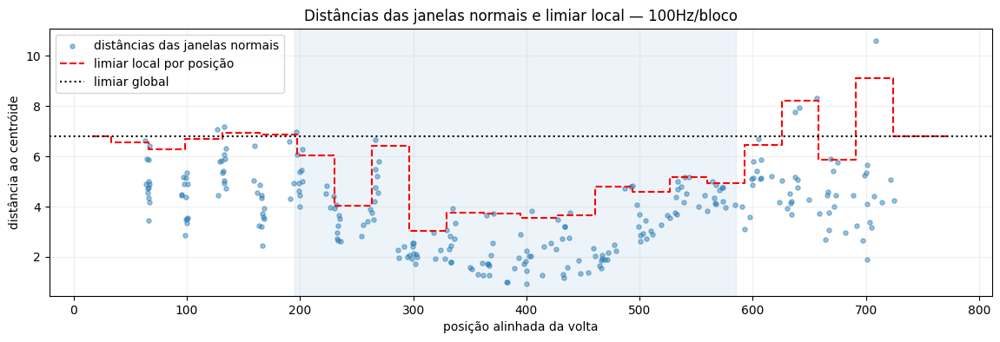

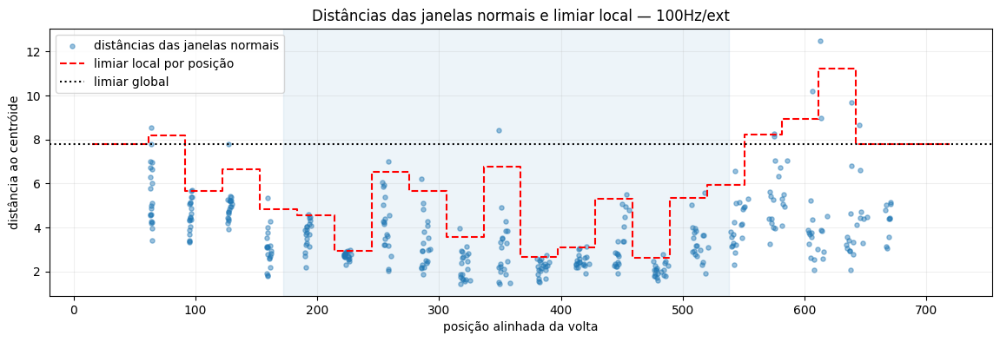

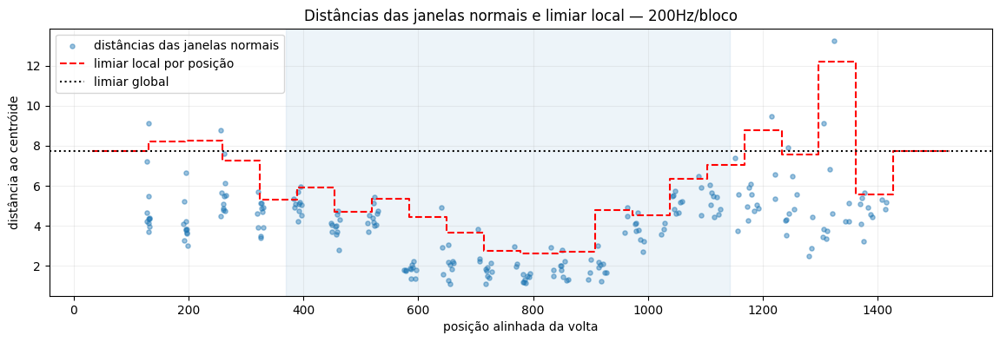

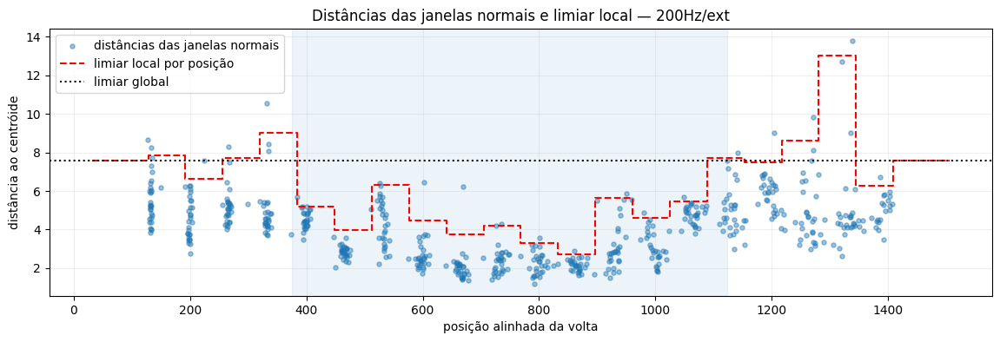

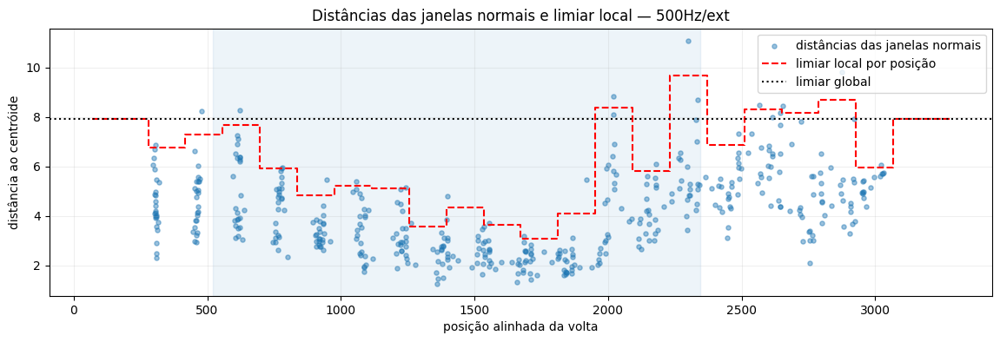

In [28]:
for freq_label in FREQUENCIAS:
    for tipo in TIPOS_COLETA:
        if freq_label not in modelos or tipo not in modelos[freq_label]:
            continue
        plot_limiares_normais(modelos[freq_label][tipo])

## Detecção e pós-processamento


In [29]:
def transformar_features(X, modelo):
    """Aplica o StandardScaler e o PCA já ajustados às features de novas janelas."""
    return modelo['pca'].transform(modelo['scaler'].transform(X))


def aplicar_pos_processamento(det_df, modelo):
    """
    Consolida janelas acima do limiar em detecções confirmadas.
    
    Exige quantidade mínima de janelas consecutivas, comprimento alinhado mínimo e score médio mínimo.
    """
    det_df = det_df.copy()
    det_df['score'] = det_df['distancia'] / det_df['limiar']
    det_df['anomalia_bruta'] = det_df['score'] >= 1.0
    det_df['anomalia'] = False

    idxs = det_df.index[det_df['anomalia_bruta']].tolist()
    if not idxs:
        return det_df

    grupos = []
    atual = [idxs[0]]
    for idx in idxs[1:]:
        prev = atual[-1]
        gap_ordem = int(det_df.loc[idx, 'id_janela']) - int(det_df.loc[prev, 'id_janela']) - 1
        if gap_ordem <= MAX_GAP_ENTRE_JANELAS:
            atual.append(idx)
        else:
            grupos.append(atual)
            atual = [idx]
    grupos.append(atual)

    for grupo_idxs in grupos:
        if len(grupo_idxs) < MIN_JANELAS_CONSECUTIVAS:
            continue

        ini = int(np.nanmin(det_df.loc[grupo_idxs, 'inicio_alinhado']))
        fim = int(np.nanmax(det_df.loc[grupo_idxs, 'fim_alinhado']))
        comprimento = fim - ini

        if comprimento < modelo['min_comprimento']:
            continue

        score_medio = float(det_df.loc[grupo_idxs, 'score'].mean())
        if score_medio < SCORE_MIN_INTERVALO:
            continue

        det_df.loc[grupo_idxs, 'anomalia'] = True

    return det_df

In [30]:
def detectar_em_df(df, mapa, nome, grupo, modelo):
    """
    Executa a detecção em uma coleta já pré-processada.
    
    Extrai e transforma as features, calcula a distância ao centroide mais próximo, seleciona o limiar da posição e aplica o pós-processamento.
    """
    X, meta, _ = processar_lista_janelas(
        [df],
        [mapa],
        [nome],
        grupo=grupo,
        freq_label=modelo['freq'],
        tipo=modelo['tipo']
    )

    if len(X) == 0:
        return pd.DataFrame()

    X_pca = transformar_features(X, modelo)
    dist = np.min(modelo['kmeans'].transform(X_pca), axis=1)
    clusters = modelo['kmeans'].predict(X_pca)

    det = meta.copy()
    det['distancia'] = dist
    det['cluster'] = clusters

    df_limiares = modelo['df_limiares']
    limiares = []
    for b in det['bin_pos'].values:
        row = df_limiares[df_limiares['bin_pos'] == b]
        if len(row):
            limiares.append(float(row['limiar_local'].iloc[0]))
        else:
            limiares.append(float(modelo['limiar_global']))
    det['limiar'] = limiares
    det['id_janela'] = np.arange(len(det))

    return aplicar_pos_processamento(det, modelo)


def intervalos_detectados(det_df):
    """Reúne e mescla os intervalos alinhados das janelas confirmadas como anômalas."""
    if det_df is None or len(det_df) == 0 or 'anomalia' not in det_df:
        return []

    intervalos = []
    for _, row in det_df[det_df['anomalia']].iterrows():
        a = int(row['inicio_alinhado'])
        b = int(row['fim_alinhado'])
        if np.isfinite(a) and np.isfinite(b):
            intervalos.append((a, b))
    return merge_intervals(intervalos, max_gap=0)


def avaliar_resultado_arquivo(det_df, grupo=''):
    """Resume a presença de detecção em um arquivo e classifica o status conforme o grupo normal ou anômalo."""
    ints = intervalos_detectados(det_df)
    tem_det = len(ints) > 0

    if grupo == GRUPO_NORMAL:
        status = 'falso_positivo' if tem_det else 'verdadeiro_negativo'
    else:
        status = 'detectou_anomalia' if tem_det else 'sem_deteccao'

    return {
        'grupo': grupo,
        'n_janelas': len(det_df),
        'n_janelas_anomalias': int(det_df['anomalia'].sum()) if len(det_df) else 0,
        'intervalos_detectados': ints,
        'status': status,
    }


def detectar_grupo(freq_label, tipo, grupo, modelo):
    """Executa a detecção em todos os arquivos de um grupo e retorna os resumos e DataFrames por janela."""
    dfs = dados[freq_label][tipo][grupo]['dfs']
    mapas = dados[freq_label][tipo][grupo]['dtw_maps']
    arquivos = dados[freq_label][tipo][grupo]['arquivos']

    dets = []
    rows = []

    for i, (df, mapa, arq) in enumerate(zip(dfs, mapas, arquivos)):
        det_df = detectar_em_df(df, mapa, nome=arq, grupo=grupo, modelo=modelo)
        dets.append(det_df)
        r = avaliar_resultado_arquivo(det_df, grupo=grupo)
        r['freq'] = freq_label
        r['tipo'] = tipo
        r['arquivo_idx'] = i
        r['arquivo'] = os.path.basename(arq)
        rows.append(r)

    return pd.DataFrame(rows), dets

### Executar a detecção em todos os grupos

In [31]:
resultados = {}

for freq_label in FREQUENCIAS:
    resultados[freq_label] = {}
    for tipo in TIPOS_COLETA:
        if freq_label not in modelos or tipo not in modelos[freq_label]:
            continue
        modelo = modelos[freq_label][tipo]
        if modelo is None:
            continue

        resumos = {}
        deteccoes = {}

        resumos[GRUPO_NORMAL], deteccoes[GRUPO_NORMAL] = detectar_grupo(freq_label, tipo, GRUPO_NORMAL, modelo)
        for grupo in GRUPOS_ANOMALIA:
            resumos[grupo], deteccoes[grupo] = detectar_grupo(freq_label, tipo, grupo, modelo)

        resumo_arquivos = pd.concat(resumos.values(), ignore_index=True)

        resultados[freq_label][tipo] = {
            'modelo': modelo,
            'resumos': resumos,
            'deteccoes': deteccoes,
            'resumo_arquivos': resumo_arquivos,
        }

        print(f'{freq_label}/{tipo}')
        display(resumo_arquivos)

100Hz/bloco


,grupo,n_janelas,n_janelas_anomalias,intervalos_detectados,status,freq,tipo,arquivo_idx,arquivo
0,alinhado,21,0,[],verdadeiro_negativo,100Hz,bloco,0,log_tcp_2026-05-17_18-22-04_192.168.1.138.csv
1,alinhado,21,0,[],verdadeiro_negativo,100Hz,bloco,1,log_tcp_2026-05-17_18-22-11_192.168.1.138.csv
2,alinhado,20,0,[],verdadeiro_negativo,100Hz,bloco,2,log_tcp_2026-05-17_18-22-19_192.168.1.138.csv
3,alinhado,21,0,[],verdadeiro_negativo,100Hz,bloco,3,log_tcp_2026-05-17_18-22-27_192.168.1.138.csv
4,alinhado,21,0,[],verdadeiro_negativo,100Hz,bloco,4,log_tcp_2026-05-17_18-22-34_192.168.1.138.csv
5,alinhado,20,0,[],verdadeiro_negativo,100Hz,bloco,5,log_tcp_2026-05-17_18-22-42_192.168.1.138.csv
6,alinhado,21,0,[],verdadeiro_negativo,100Hz,bloco,6,log_tcp_2026-05-17_18-22-49_192.168.1.138.csv
7,alinhado,20,0,[],verdadeiro_negativo,100Hz,bloco,7,log_tcp_2026-05-17_18-23-20_192.168.1.138.csv
8,alinhado,20,0,[],verdadeiro_negativo,100Hz,bloco,8,log_tcp_2026-05-17_18-23-27_192.168.1.138.csv
9,alinhado,20,0,[],verdadeiro_negativo,100Hz,bloco,9,log_tcp_2026-05-17_18-23-35_192.168.1.138.csv


100Hz/ext


,grupo,n_janelas,n_janelas_anomalias,intervalos_detectados,status,freq,tipo,arquivo_idx,arquivo
0,alinhado,19,0,[],verdadeiro_negativo,100Hz,ext,0,log_tcp_2026-05-17_18-48-25_192.168.1.138.csv
1,alinhado,19,0,[],verdadeiro_negativo,100Hz,ext,1,log_tcp_2026-05-17_18-48-33_192.168.1.138.csv
2,alinhado,20,3,"[(222, 411)]",falso_positivo,100Hz,ext,2,log_tcp_2026-05-17_18-48-40_192.168.1.138.csv
3,alinhado,19,0,[],verdadeiro_negativo,100Hz,ext,3,log_tcp_2026-05-17_18-48-47_192.168.1.138.csv
4,alinhado,20,0,[],verdadeiro_negativo,100Hz,ext,4,log_tcp_2026-05-17_18-48-55_192.168.1.138.csv
5,alinhado,20,0,[],verdadeiro_negativo,100Hz,ext,5,log_tcp_2026-05-17_18-49-02_192.168.1.138.csv
6,alinhado,19,0,[],verdadeiro_negativo,100Hz,ext,6,log_tcp_2026-05-17_18-49-09_192.168.1.138.csv
7,alinhado,20,0,[],verdadeiro_negativo,100Hz,ext,7,log_tcp_2026-05-17_18-49-16_192.168.1.138.csv
8,alinhado,19,0,[],verdadeiro_negativo,100Hz,ext,8,log_tcp_2026-05-17_18-49-24_192.168.1.138.csv
9,alinhado,20,0,[],verdadeiro_negativo,100Hz,ext,9,log_tcp_2026-05-17_18-49-31_192.168.1.138.csv


200Hz/bloco


,grupo,n_janelas,n_janelas_anomalias,intervalos_detectados,status,freq,tipo,arquivo_idx,arquivo
0,alinhado,21,7,"[(512, 959), (960, 1343)]",falso_positivo,200Hz,bloco,0,log_tcp_2026-05-17_20-34-10_192.168.1.138.csv
1,alinhado,21,0,[],verdadeiro_negativo,200Hz,bloco,1,log_tcp_2026-05-17_20-34-18_192.168.1.138.csv
2,alinhado,20,0,[],verdadeiro_negativo,200Hz,bloco,2,log_tcp_2026-05-17_20-34-25_192.168.1.138.csv
3,alinhado,21,0,[],verdadeiro_negativo,200Hz,bloco,3,log_tcp_2026-05-17_20-34-33_192.168.1.138.csv
4,alinhado,20,0,[],verdadeiro_negativo,200Hz,bloco,4,log_tcp_2026-05-17_20-34-40_192.168.1.138.csv
5,alinhado,20,0,[],verdadeiro_negativo,200Hz,bloco,5,log_tcp_2026-05-17_20-34-48_192.168.1.138.csv
6,alinhado,20,0,[],verdadeiro_negativo,200Hz,bloco,6,log_tcp_2026-05-17_20-35-21_192.168.1.138.csv
7,alinhado,20,0,[],verdadeiro_negativo,200Hz,bloco,7,log_tcp_2026-05-17_20-35-33_192.168.1.138.csv
8,alinhado,20,0,[],verdadeiro_negativo,200Hz,bloco,8,log_tcp_2026-05-17_20-35-40_192.168.1.138.csv
9,alinhado,20,0,[],verdadeiro_negativo,200Hz,bloco,9,log_tcp_2026-05-17_20-35-48_192.168.1.138.csv


200Hz/ext


,grupo,n_janelas,n_janelas_anomalias,intervalos_detectados,status,freq,tipo,arquivo_idx,arquivo
0,alinhado,21,0,[],verdadeiro_negativo,200Hz,ext,0,log_tcp_2026-05-17_19-27-53_192.168.1.138.csv
1,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,1,log_tcp_2026-05-17_19-28-01_192.168.1.138.csv
2,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,2,log_tcp_2026-05-17_19-28-08_192.168.1.138.csv
3,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,3,log_tcp_2026-05-17_19-28-16_192.168.1.138.csv
4,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,4,log_tcp_2026-05-17_19-28-23_192.168.1.138.csv
5,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,5,log_tcp_2026-05-17_19-28-30_192.168.1.138.csv
6,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,6,log_tcp_2026-05-17_19-28-38_192.168.1.138.csv
7,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,7,log_tcp_2026-05-17_19-28-45_192.168.1.138.csv
8,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,8,log_tcp_2026-05-17_19-28-52_192.168.1.138.csv
9,alinhado,20,0,[],verdadeiro_negativo,200Hz,ext,9,log_tcp_2026-05-17_19-29-00_192.168.1.138.csv


500Hz/ext


,grupo,n_janelas,n_janelas_anomalias,intervalos_detectados,status,freq,tipo,arquivo_idx,arquivo
0,alinhado,17,0,[],verdadeiro_negativo,500Hz,ext,0,log_tcp_2026-05-17_21-02-42_192.168.1.138.csv
1,alinhado,18,0,[],verdadeiro_negativo,500Hz,ext,1,log_tcp_2026-05-17_21-02-49_192.168.1.138.csv
2,alinhado,18,0,[],verdadeiro_negativo,500Hz,ext,2,log_tcp_2026-05-17_21-02-58_192.168.1.138.csv
3,alinhado,18,0,[],verdadeiro_negativo,500Hz,ext,3,log_tcp_2026-05-17_21-03-11_192.168.1.138.csv
4,alinhado,18,0,[],verdadeiro_negativo,500Hz,ext,4,log_tcp_2026-05-17_21-03-19_192.168.1.138.csv
5,alinhado,18,3,"[(932, 1864)]",falso_positivo,500Hz,ext,5,log_tcp_2026-05-17_21-03-26_192.168.1.138.csv
6,alinhado,19,0,[],verdadeiro_negativo,500Hz,ext,6,log_tcp_2026-05-17_21-03-33_192.168.1.138.csv
7,alinhado,18,0,[],verdadeiro_negativo,500Hz,ext,7,log_tcp_2026-05-17_21-03-42_192.168.1.138.csv
8,alinhado,19,0,[],verdadeiro_negativo,500Hz,ext,8,log_tcp_2026-05-17_21-03-55_192.168.1.138.csv
9,alinhado,18,0,[],verdadeiro_negativo,500Hz,ext,9,log_tcp_2026-05-17_21-04-04_192.168.1.138.csv


## Resumo por arquivo e métricas por grupo


In [32]:
def metricas_por_grupo(resumo_arquivos):
    """Agrega os status por grupo, calculando taxa de falso positivo nos normais e taxa de detecção nos anômalos."""
    rows = []
    for grupo, g in resumo_arquivos.groupby('grupo', sort=False):
        total = len(g)
        row = {'grupo': grupo, 'n_arquivos': total}
        cont = g['status'].value_counts().to_dict()
        if grupo == GRUPO_NORMAL:
            row['verdadeiro_negativo'] = int(cont.get('verdadeiro_negativo', 0))
            row['falso_positivo'] = int(cont.get('falso_positivo', 0))
            row['taxa_fp'] = row['falso_positivo'] / total if total else np.nan
            row['detectou_anomalia'] = np.nan
            row['sem_deteccao'] = np.nan
            row['taxa_detectou'] = np.nan
        else:
            row['verdadeiro_negativo'] = np.nan
            row['falso_positivo'] = np.nan
            row['taxa_fp'] = np.nan
            row['detectou_anomalia'] = int(cont.get('detectou_anomalia', 0))
            row['sem_deteccao'] = int(cont.get('sem_deteccao', 0))
            row['taxa_detectou'] = row['detectou_anomalia'] / total if total else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

In [33]:
metricas = {}

for freq_label in resultados:
    metricas[freq_label] = {}
    for tipo in resultados[freq_label]:
        resumo_arquivos = resultados[freq_label][tipo]['resumo_arquivos']
        met = metricas_por_grupo(resumo_arquivos)
        metricas[freq_label][tipo] = met

        print(f'\nMétricas — {freq_label}/{tipo}')
        display(met)


Métricas — 100Hz/bloco


,grupo,n_arquivos,verdadeiro_negativo,falso_positivo,taxa_fp,detectou_anomalia,sem_deteccao,taxa_detectou
0,alinhado,13,12.0,1.0,0.076923,NaN,NaN,NaN
1,an_0_1,15,NaN,NaN,NaN,13.0,2.0,0.866667
2,an_1_2,15,NaN,NaN,NaN,15.0,0.0,1.000000
3,an_2_3,10,NaN,NaN,NaN,10.0,0.0,1.000000
4,an_3_4,9,NaN,NaN,NaN,9.0,0.0,1.000000
5,an_4_0,6,NaN,NaN,NaN,6.0,0.0,1.000000



Métricas — 100Hz/ext


,grupo,n_arquivos,verdadeiro_negativo,falso_positivo,taxa_fp,detectou_anomalia,sem_deteccao,taxa_detectou
0,alinhado,20,19.0,1.0,0.05,NaN,NaN,NaN
1,an_0_1,18,NaN,NaN,NaN,18.0,0.0,1.0
2,an_1_2,11,NaN,NaN,NaN,11.0,0.0,1.0
3,an_2_3,15,NaN,NaN,NaN,15.0,0.0,1.0
4,an_3_4,10,NaN,NaN,NaN,10.0,0.0,1.0
5,an_4_0,12,NaN,NaN,NaN,12.0,0.0,1.0



Métricas — 200Hz/bloco


,grupo,n_arquivos,verdadeiro_negativo,falso_positivo,taxa_fp,detectou_anomalia,sem_deteccao,taxa_detectou
0,alinhado,11,10.0,1.0,0.090909,NaN,NaN,NaN
1,an_0_1,14,NaN,NaN,NaN,3.0,11.0,0.214286
2,an_1_2,10,NaN,NaN,NaN,0.0,10.0,0.000000
3,an_2_3,9,NaN,NaN,NaN,2.0,7.0,0.222222
4,an_3_4,10,NaN,NaN,NaN,2.0,8.0,0.200000
5,an_4_0,12,NaN,NaN,NaN,12.0,0.0,1.000000



Métricas — 200Hz/ext


,grupo,n_arquivos,verdadeiro_negativo,falso_positivo,taxa_fp,detectou_anomalia,sem_deteccao,taxa_detectou
0,alinhado,30,29.0,1.0,0.033333,NaN,NaN,NaN
1,an_0_1,21,NaN,NaN,NaN,21.0,0.0,1.0
2,an_1_2,18,NaN,NaN,NaN,18.0,0.0,1.0
3,an_2_3,11,NaN,NaN,NaN,11.0,0.0,1.0
4,an_3_4,13,NaN,NaN,NaN,13.0,0.0,1.0
5,an_4_0,11,NaN,NaN,NaN,11.0,0.0,1.0



Métricas — 500Hz/ext


,grupo,n_arquivos,verdadeiro_negativo,falso_positivo,taxa_fp,detectou_anomalia,sem_deteccao,taxa_detectou
0,alinhado,25,24.0,1.0,0.04,NaN,NaN,NaN
1,an_0_1,18,NaN,NaN,NaN,18.0,0.0,1.0
2,an_1_2,10,NaN,NaN,NaN,10.0,0.0,1.0
3,an_2_3,12,NaN,NaN,NaN,12.0,0.0,1.0
4,an_3_4,9,NaN,NaN,NaN,9.0,0.0,1.0
5,an_4_0,10,NaN,NaN,NaN,10.0,0.0,1.0


## Diagnóstico visual por arquivo

In [34]:
def raio_por_frequencia(freq_label):
    """Define o raio visual usado ao destacar o centro de uma detecção em cada frequência."""
    if str(freq_label).startswith('500'):
        return 100
    if str(freq_label).startswith('100'):
        return 25
    return 50


def detectar_regiao_topo_por_extremos_angle(df, x_map=None, col='angle_y_deg'):
    """Projeta os extremos de ``angle_y_deg`` no eixo alinhado para estimar a parte superior da correia."""
    if df is None or len(df) == 0 or col not in df.columns:
        return []

    ang = df[col].values.astype(float)

    if np.all(~np.isfinite(ang)):
        return []

    idx_min = int(np.nanargmin(ang))
    idx_max = int(np.nanargmax(ang))

    if x_map is None:
        p_min = idx_min
        p_max = idx_max
    else:
        p_min = int(round(x_map[idx_min]))
        p_max = int(round(x_map[idx_max]))

    a, b = sorted([p_min, p_max])
    return [(a, b)]


def centro_maior_interseccao_intervalos(intervalos, n_ref=None):
    """Obtém o centro da região coberta pelo maior número de intervalos."""
    if intervalos is None or len(intervalos) == 0:
        return None

    intervalos_validos = []
    for a, b in intervalos:
        if not np.isfinite(a) or not np.isfinite(b):
            continue
        a = int(round(a))
        b = int(round(b))
        if b < a:
            a, b = b, a
        intervalos_validos.append((a, b))

    if len(intervalos_validos) == 0:
        return None

    if n_ref is None:
        n_ref = max(b for _, b in intervalos_validos) + 1

    coverage = np.zeros(int(n_ref))

    for a, b in intervalos_validos:
        a = max(0, min(int(n_ref) - 1, a))
        b = max(0, min(int(n_ref) - 1, b))
        coverage[a:b+1] += 1

    max_cov = np.max(coverage)
    if max_cov <= 0:
        return None

    candidatos = np.where(coverage == max_cov)[0]
    centro = int(round((candidatos[0] + candidatos[-1]) / 2))
    return centro


def centros_deteccao_por_interseccao(det_df, n_ref=None):
    """Calcula um centro representativo para cada sequência de janelas anômalas confirmadas."""
    if det_df is None or len(det_df) == 0 or 'anomalia' not in det_df:
        return []

    det = det_df[det_df['anomalia']].copy()
    if len(det) == 0:
        return []

    det = det.sort_values('id_janela')

    grupos = []
    atual = [det.index[0]]

    for idx in det.index[1:]:
        prev = atual[-1]
        gap = int(det_df.loc[idx, 'id_janela']) - int(det_df.loc[prev, 'id_janela']) - 1
        if gap <= MAX_GAP_ENTRE_JANELAS:
            atual.append(idx)
        else:
            grupos.append(atual)
            atual = [idx]

    grupos.append(atual)

    centros = []

    for grupo_idxs in grupos:
        intervalos = []
        for idx in grupo_idxs:
            intervalos.append((
                det_df.loc[idx, 'inicio_alinhado'],
                det_df.loc[idx, 'fim_alinhado']
            ))

        centro = centro_maior_interseccao_intervalos(intervalos, n_ref=n_ref)
        if centro is not None:
            centros.append(centro)

    return centros

In [35]:
def plotar_diagnostico_arquivo(freq_label, tipo, nome_grupo, idx=0):
    """Plota sinais brutos, sinais processados, ângulo, distâncias, limiares e regiões detectadas de um arquivo."""
    res = resultados[freq_label][tipo]
    df = dados[freq_label][tipo][nome_grupo]['dfs'][idx]
    mapa = dados[freq_label][tipo][nome_grupo]['dtw_maps'][idx]
    det_df = res['deteccoes'][nome_grupo][idx]
    resumo = res['resumos'][nome_grupo].iloc[idx].to_dict()
    df_ref = dados[freq_label][tipo]['df_ref']

    raio = raio_por_frequencia(freq_label)

    titulo = f'{freq_label}/{tipo}/{nome_grupo}[{idx}] — {resumo.get("status", "")}'

    x_al = mapa['raw_to_ref']
    ordem = np.argsort(x_al)

    top_regions = detectar_regiao_topo_por_extremos_angle(df, x_map=x_al)
    det_centros = centros_deteccao_por_interseccao(det_df, n_ref=len(df_ref))

    fig, axes = plt.subplots(4, 1, figsize=(18, 12), sharex=True)

    for col in EIXOS_RAW:
        axes[0].plot(x_al[ordem], df[col].values[ordem], label=col, linewidth=1)
    axes[0].set_title('Sinais brutos — ' + titulo)
    axes[0].set_ylabel('bruto')
    axes[0].legend(loc='upper right')
    axes[0].grid(alpha=0.2)

    axes[1].plot(x_al[ordem], df['acc_hp_mag'].values[ordem], label='acc_hp_mag', color='black', linewidth=1.5)
    for col in EIXOS_HP:
        axes[1].plot(x_al[ordem], df[col].values[ordem], label=col, linewidth=0.8, alpha=0.35)
    axes[1].set_title('Sinais processados usados nas features')
    axes[1].set_ylabel('m/s²')
    axes[1].legend(loc='upper right')
    axes[1].grid(alpha=0.2)

    axes[2].plot(x_al[ordem], df['angle_y_deg'].values[ordem], label='angle_y_deg', color='purple', linewidth=1.2)
    axes[2].set_title('Ângulo estimado — eixo Y')
    axes[2].set_ylabel('graus')
    axes[2].legend(loc='upper right')
    axes[2].grid(alpha=0.2)

    axes[3].plot(det_df['centro_alinhado'], det_df['distancia'], color='blue', label='distância ao KMeans')
    axes[3].step(det_df['centro_alinhado'], det_df['limiar'], where='mid', color='red', linestyle='--', label='limiar local por posição')

    if 'anomalia_bruta' in det_df:
        bruto = det_df[det_df['anomalia_bruta']]
        axes[3].scatter(
            bruto['centro_alinhado'],
            bruto['distancia'],
            s=18,
            alpha=0.35,
            label='janela acima do limiar antes do filtro'
        )

    if det_centros:
        det_filtrado = det_df[det_df['anomalia']]
        y_centros = []
        for c in det_centros:
            idx_mais_proximo = np.argmin(np.abs(det_filtrado['centro_alinhado'].values - c))
            y_centros.append(det_filtrado.iloc[idx_mais_proximo]['distancia'])

        axes[3].scatter(
            det_centros,
            y_centros,
            color='red',
            s=70,
            marker='x',
            linewidths=2,
            label='centro da detecção após filtro'
        )

    axes[3].set_title('Distância e limiar local')
    axes[3].set_ylabel('distância')
    axes[3].set_xlabel('índice da amostra projetado na referência')
    axes[3].legend(loc='upper right')
    axes[3].grid(alpha=0.2)

    for ax in axes:
        for j, (a, b) in enumerate(top_regions):
            ax.axvspan(
                a,
                b,
                color='tab:blue',
                alpha=0.06,
                label='parte superior estimada pelo angle_y_deg do arquivo' if ax is axes[0] and j == 0 else None
            )

        for j, c in enumerate(det_centros):
            ax.axvspan(
                c - raio,
                c + raio,
                color='red',
                alpha=0.18,
                label=f'centro ± {raio} da anomalia detectada' if ax is axes[0] and j == 0 else None
            )

    axes[0].legend(loc='upper right')
    plt.tight_layout()
    plt.show()

### Gerar diagnósticos para os arquivos selecionados

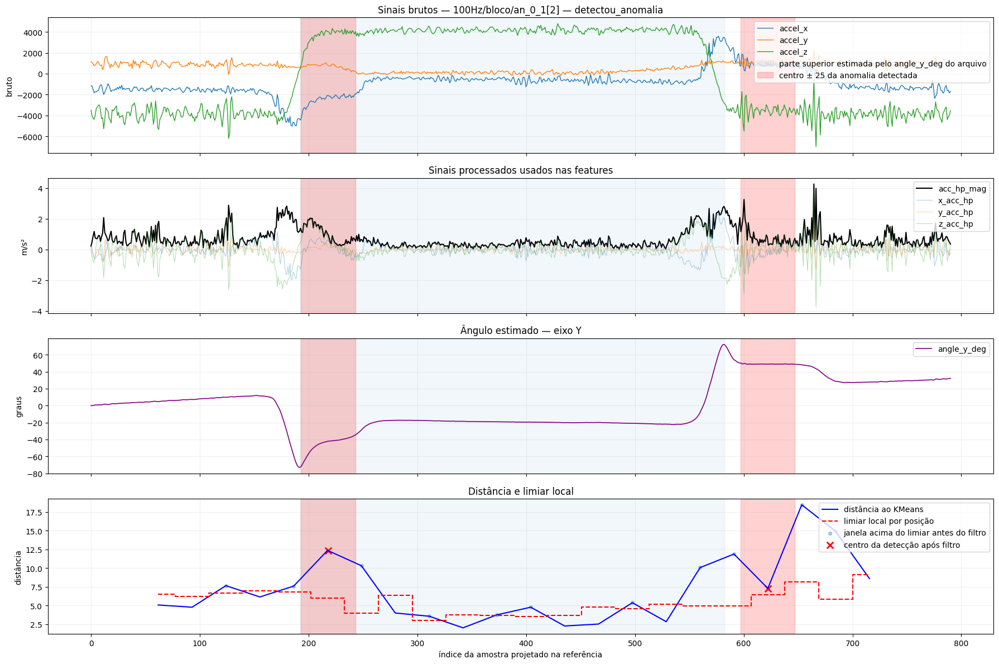

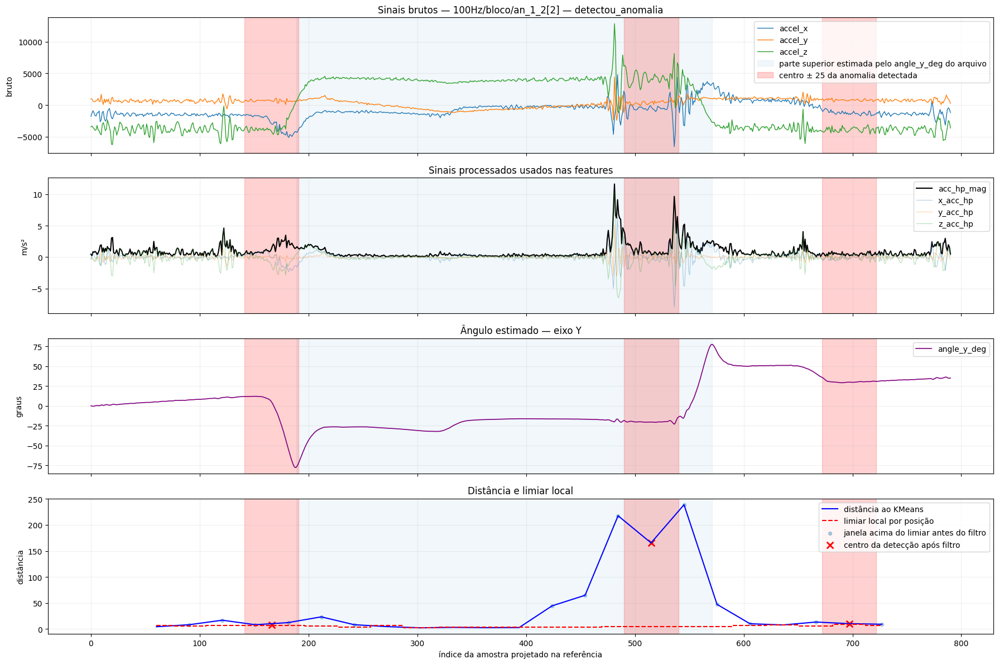

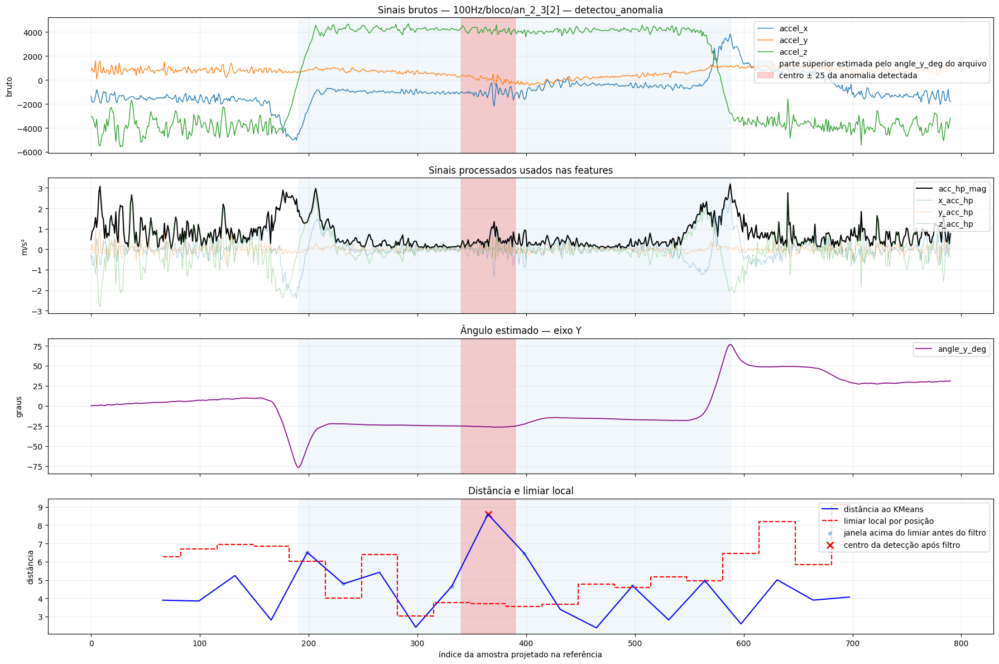

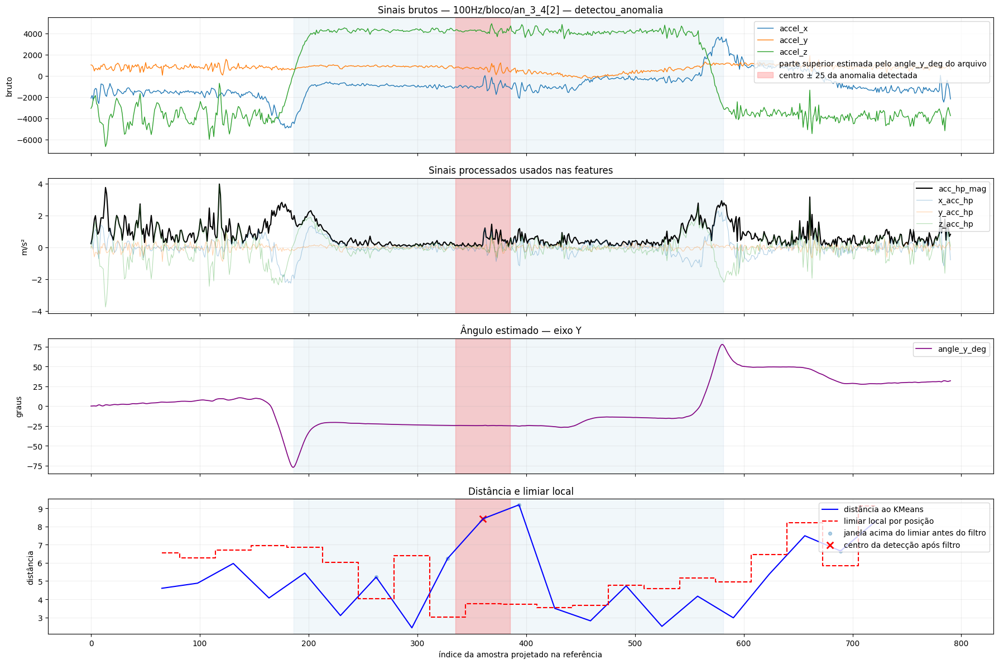

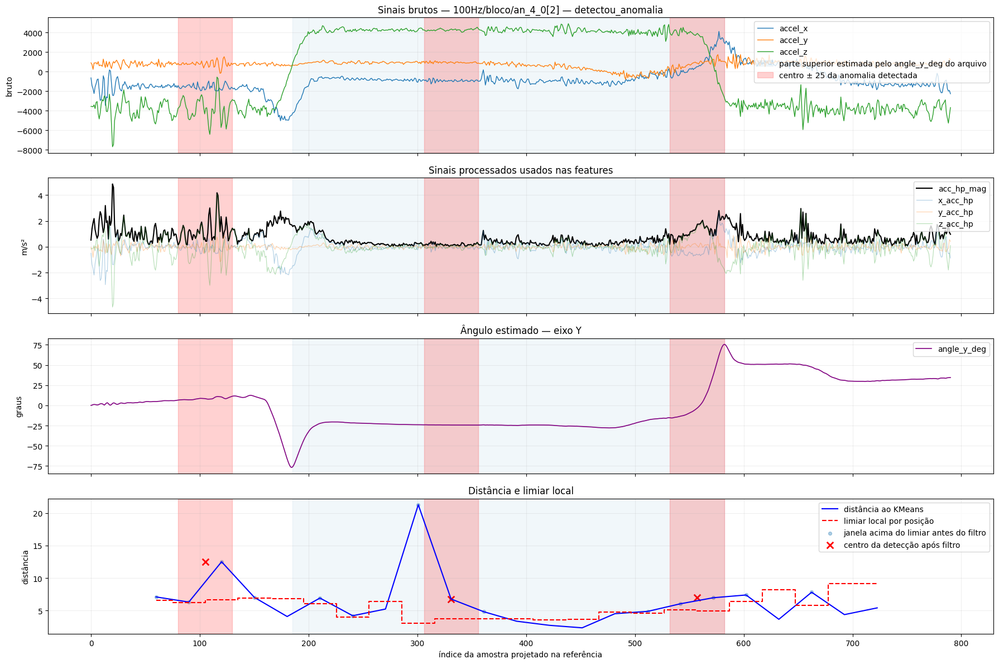

...

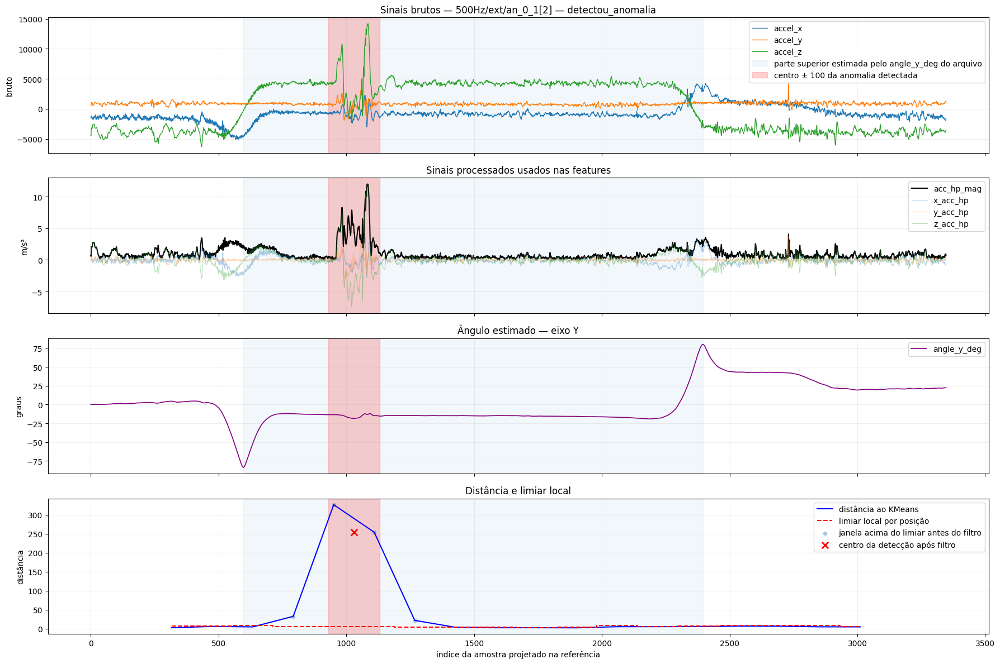

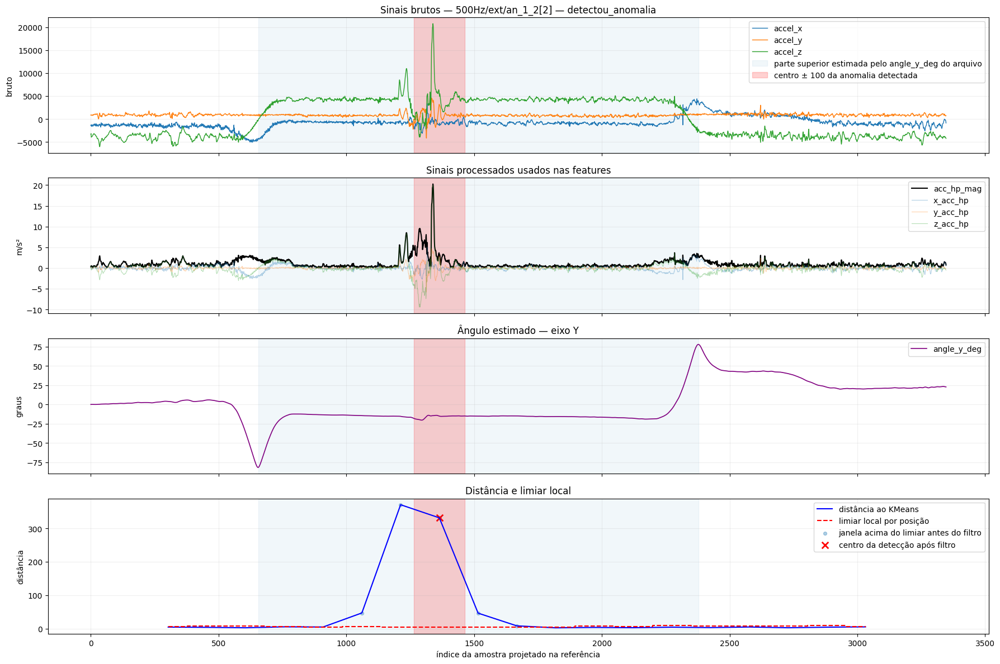

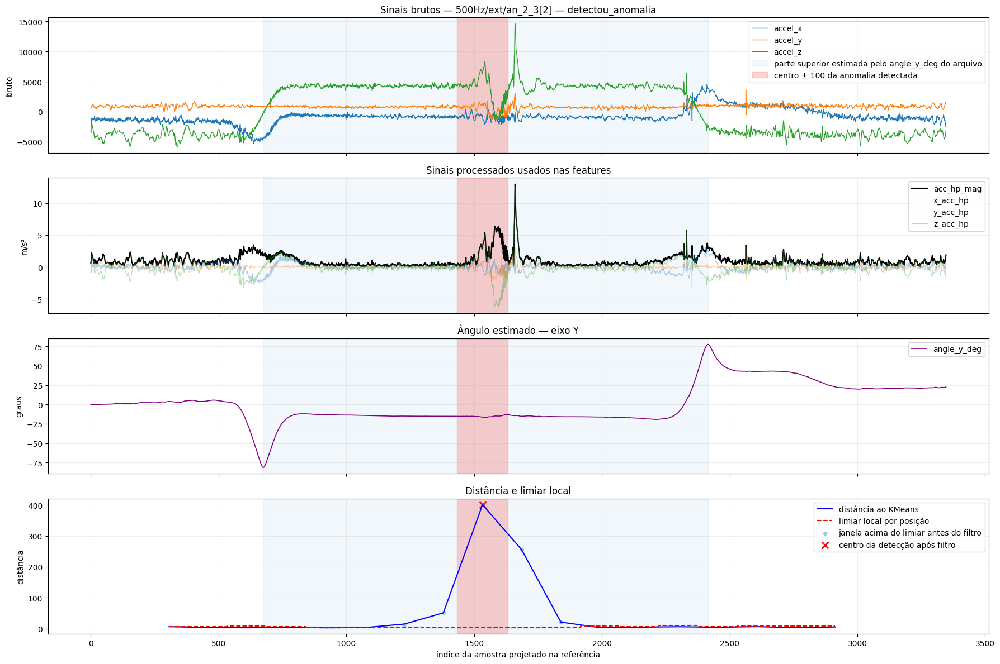

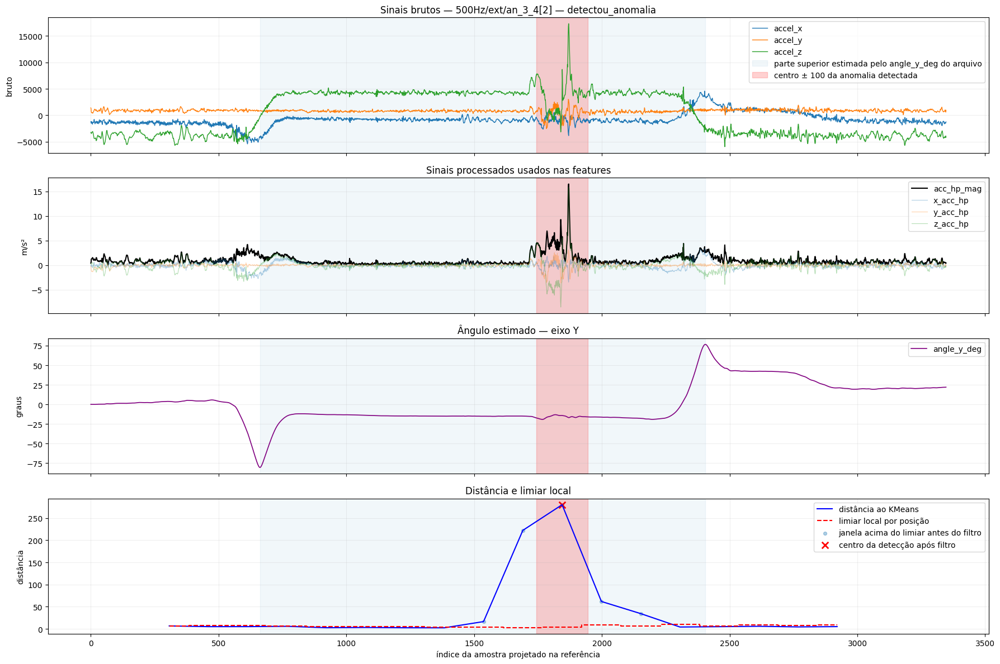

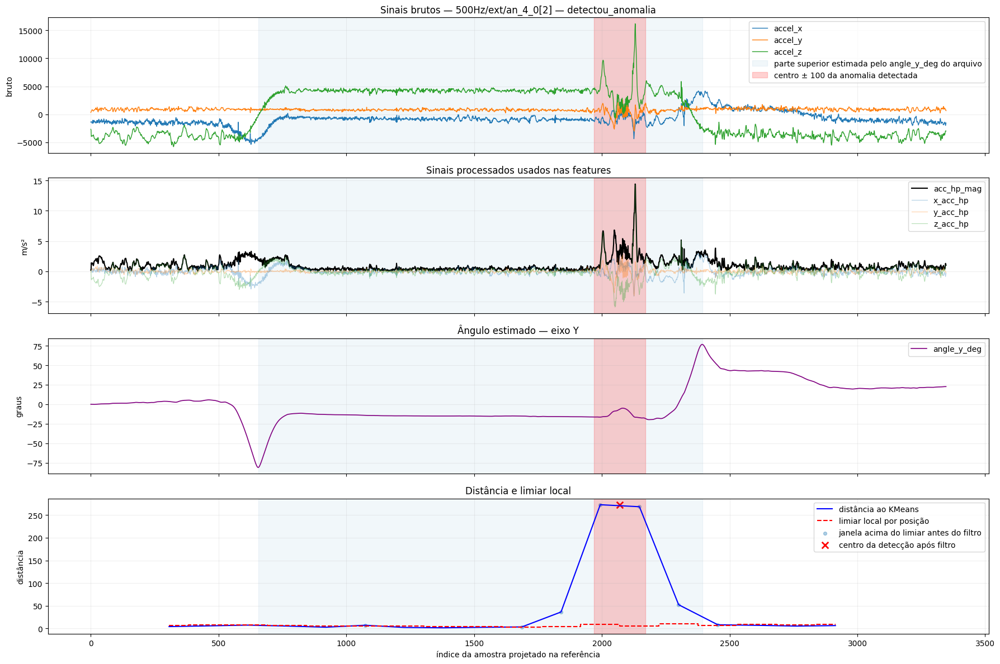

In [36]:
for freq_label in resultados:
    for tipo in resultados[freq_label]:
        for grupo in GRUPOS_ANOMALIA:
            if len(dados[freq_label][tipo][grupo]['dfs']) > 0:
                plotar_diagnostico_arquivo(freq_label, tipo, grupo, idx=2)

## Distribuição das detecções por grupo


In [37]:
def extremos_angle_df(df, col='angle_y_deg'):
    """Retorna os índices ordenados dos valores mínimo e máximo de ``angle_y_deg``."""
    if df is None or len(df) == 0 or col not in df.columns:
        return None

    ang = df[col].values.astype(float)

    if np.all(~np.isfinite(ang)):
        return None

    idx_min = int(np.nanargmin(ang))
    idx_max = int(np.nanargmax(ang))

    a, b = sorted([idx_min, idx_max])
    return a, b


def regiao_topo_mediana_alinhados_categoria(freq_label, tipo):
    """Estima a região superior mediana dos arquivos normais e escolhe uma coleta angular representativa."""
    intervalos = []
    candidatos_ref = []

    if freq_label not in dados:
        return None, None, None

    if tipo not in dados[freq_label]:
        return None, None, None

    if 'alinhado' not in dados[freq_label][tipo]:
        return None, None, None

    dfs = dados[freq_label][tipo]['alinhado']['dfs']

    for df in dfs:
        ext = extremos_angle_df(df)
        if ext is None:
            continue

        intervalos.append(ext)
        candidatos_ref.append(df)

    if len(intervalos) == 0:
        return None, None, None

    inicios = np.array([a for a, _ in intervalos])
    fins = np.array([b for _, b in intervalos])

    ini_med = int(round(np.median(inicios)))
    fim_med = int(round(np.median(fins)))

    melhor_df = None
    melhor_score = np.inf

    for df in candidatos_ref:
        ext = extremos_angle_df(df)
        if ext is None:
            continue

        a, b = ext
        score = abs(a - ini_med) + abs(b - fim_med)

        if score < melhor_score:
            melhor_score = score
            melhor_df = df

    return ini_med, fim_med, melhor_df


def heat_por_grupo(freq_label, tipo, nome_grupo):
    """Acumula, por posição da referência, quantas detecções confirmadas cobrem cada amostra."""
    res = resultados[freq_label][tipo]
    df_ref = dados[freq_label][tipo]['df_ref']
    n = len(df_ref)
    heat = np.zeros(n)

    if nome_grupo not in res['deteccoes']:
        return heat

    for det_df in res['deteccoes'][nome_grupo]:
        if det_df is None or len(det_df) == 0 or 'anomalia' not in det_df:
            continue

        det = det_df[det_df['anomalia']]
        for _, row in det.iterrows():
            a = int(round(row['inicio_alinhado']))
            b = int(round(row['fim_alinhado']))

            if b < a:
                a, b = b, a

            a = max(0, min(n - 1, a))
            b = max(0, min(n - 1, b))

            heat[a:b+1] += 1

    return heat


def centro_maior_interseccao_heat(heat):
    """Retorna o centro da faixa com contagem máxima em um vetor de cobertura."""
    if heat is None or len(heat) == 0:
        return None

    max_heat = np.max(heat)
    if max_heat <= 0:
        return None

    candidatos = np.where(heat == max_heat)[0]
    centro = int(round((candidatos[0] + candidatos[-1]) / 2))
    return centro

In [38]:
def plot_heatmap_freq_grupo(freq_label, nome_grupo):
    """Compara a distribuição espacial das detecções de bloco e ext para uma frequência e grupo."""
    fig, ax = plt.subplots(figsize=(16, 4))

    cores = {'ext': 'red', 'bloco': 'blue'}
    raio = raio_por_frequencia(freq_label)

    angle_refs = []

    for tipo in TIPOS_COLETA:
        if freq_label not in resultados or tipo not in resultados[freq_label]:
            continue

        heat = heat_por_grupo(freq_label, tipo, nome_grupo)
        x = np.arange(len(heat))

        ax.plot(
            x,
            heat,
            color=cores.get(tipo, None),
            linewidth=2,
            label=f'{tipo}'
        )

        centro = centro_maior_interseccao_heat(heat)

        if centro is not None:
            ax.axvspan(
                centro - raio,
                centro + raio,
                color=cores.get(tipo, None),
                alpha=0.18,
                label=f'{tipo}: centro ± {raio}'
            )

            ax.axvline(
                centro,
                color=cores.get(tipo, None),
                linestyle='--',
                linewidth=1.5,
                alpha=0.75
            )

        ini_topo, fim_topo, df_angle_ref = regiao_topo_mediana_alinhados_categoria(freq_label, tipo)

        if ini_topo is not None and fim_topo is not None:
            ax.axvspan(
                ini_topo,
                fim_topo,
                color=cores.get(tipo, None),
                alpha=0.05,
                label=f'{tipo}: parte superior mediana'
            )

        if df_angle_ref is not None:
            angle_refs.append((tipo, df_angle_ref))

    if len(angle_refs) > 0:
        ax2 = ax.twinx()

        for tipo, df_angle_ref in angle_refs:
            ang = df_angle_ref['angle_y_deg'].values
            ax2.plot(
                ang,
                color=cores.get(tipo, None),
                linewidth=1.0,
                alpha=0.35,
                linestyle=':',
                label=f'{tipo}: angle_y_deg'
            )

        ax2.set_ylabel('angle_y_deg')
        ax2.legend(loc='upper right')

    ax.set_title(f'Heatmap de detecções — {freq_label}/{nome_grupo}')
    ax.set_xlabel('índice da amostra')
    ax.set_ylabel('contagem')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.2)
    plt.show()

### Gerar os heatmaps

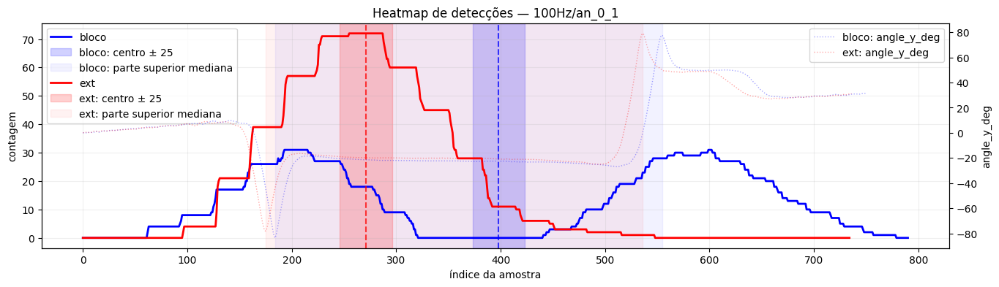

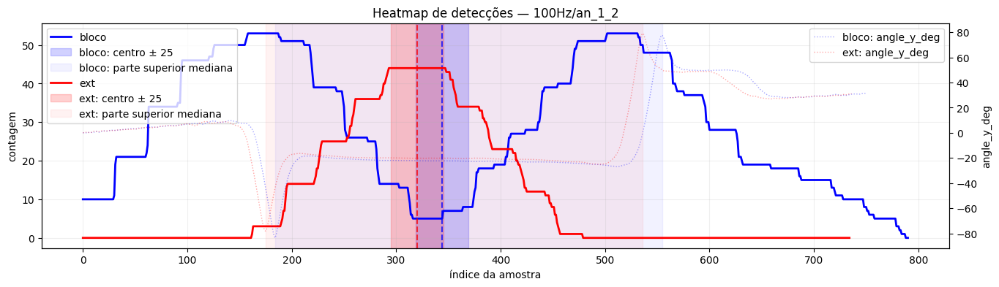

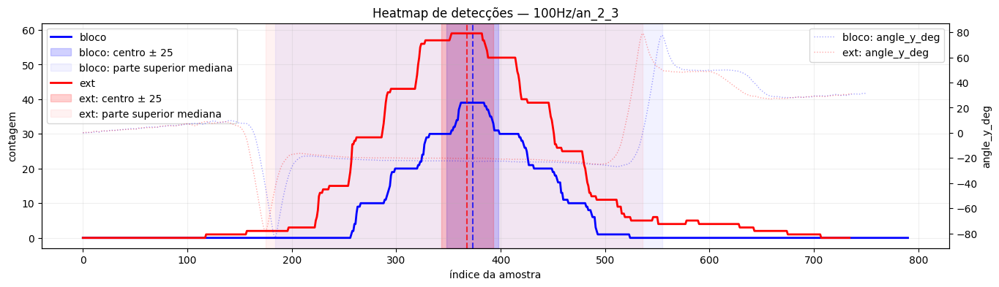

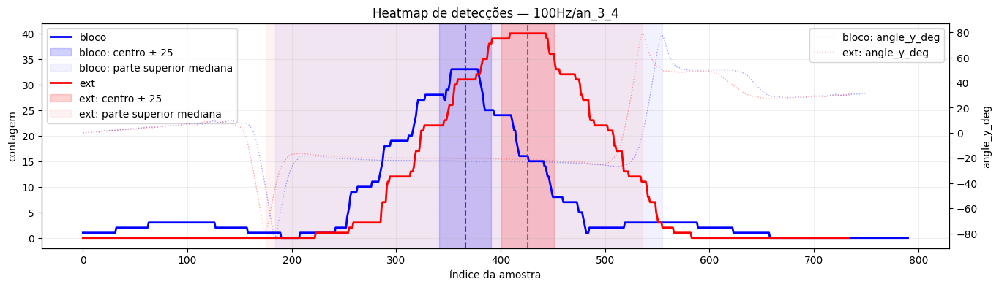

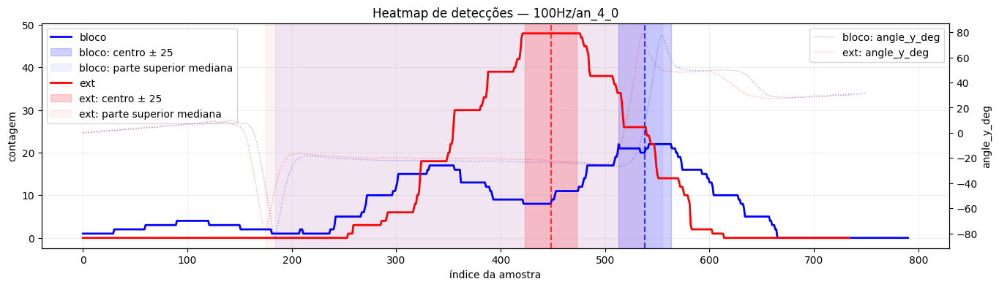

...

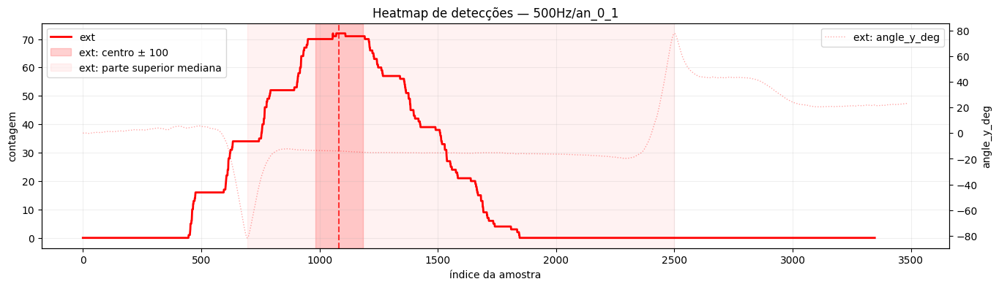

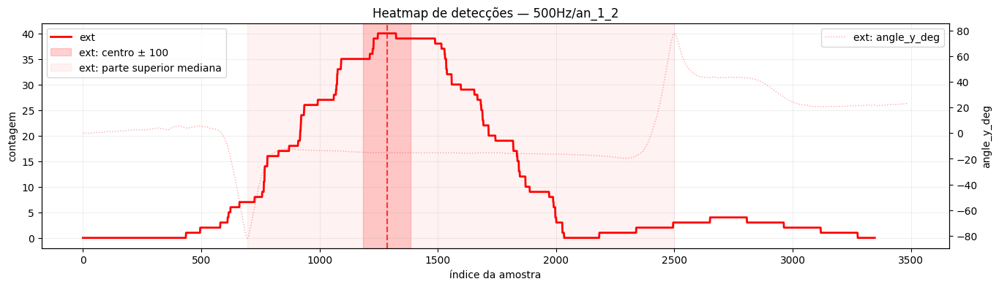

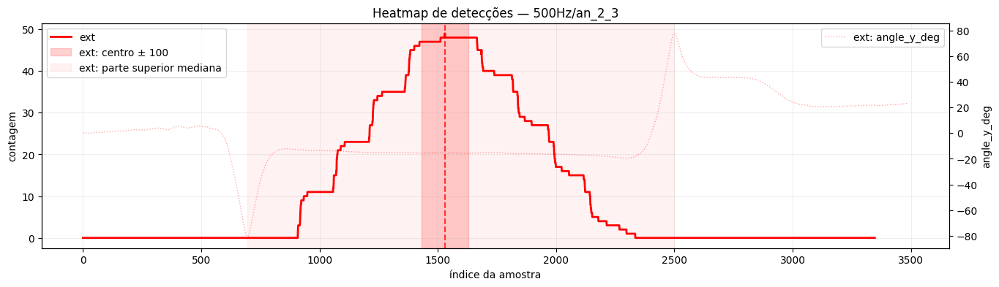

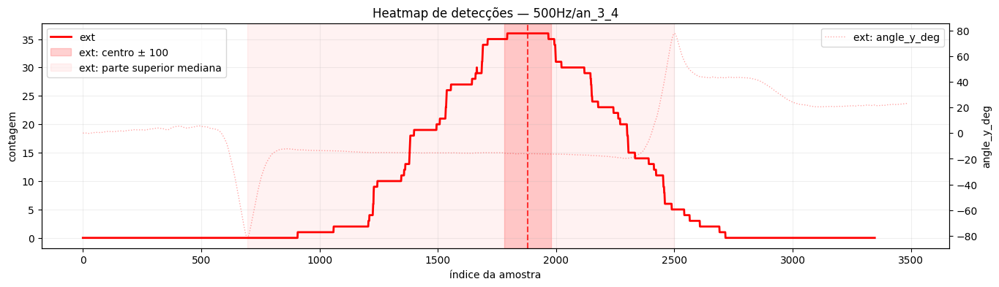

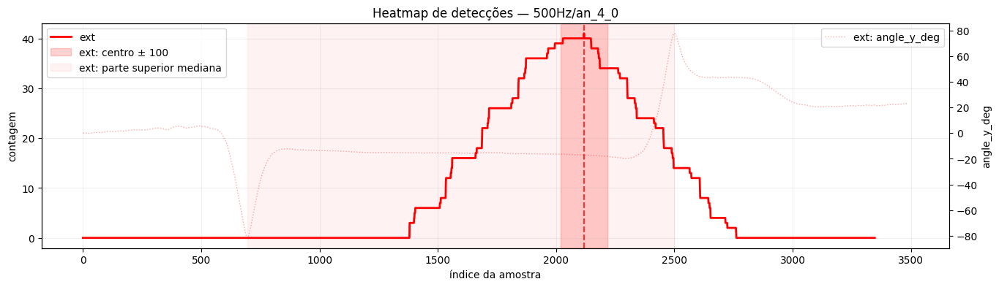

In [39]:
for freq_label in FREQUENCIAS:
    for grupo in GRUPOS_ANOMALIA:
        if freq_label in resultados:
            plot_heatmap_freq_grupo(freq_label, grupo)

## Comparação entre uma janela normal e uma janela anômala na mesma posição

In [40]:
def janela_por_centro_alinhado(df, mapa, centro_alinhado, n_janela):
    """Localiza no arquivo original a janela mais próxima de um centro definido no eixo alinhado."""
    raw_to_ref = mapa['raw_to_ref']
    raw_center = int(np.nanargmin(np.abs(raw_to_ref - centro_alinhado)))
    ini = max(0, raw_center - n_janela // 2)
    fim = min(len(df), ini + n_janela)
    ini = max(0, fim - n_janela)
    x_al = raw_to_ref[ini:fim]
    return ini, fim, x_al, df.iloc[ini:fim]


def plot_espectro_sinal(ax, sinal, label, fs, n_pad):
    """Calcula e desenha o espectro de energia de um sinal em um eixo Matplotlib."""
    sinal = np.asarray(sinal, dtype=float)
    sinal = sinal - np.mean(sinal)
    janela = np.hanning(len(sinal))
    yf = scipy.fft.rfft(sinal * janela, n=n_pad)
    freqs = scipy.fft.rfftfreq(n_pad, d=1/fs)
    energia = np.abs(yf) ** 2
    ax.plot(freqs, energia, label=label, linewidth=1.8)
    return freqs, energia


def comparar_janelas_mesma_posicao(freq_label='100Hz', tipo='ext', nome_grupo='an_3_4', idx_anom=0, idx_normal=0, centro=450, col='acc_hp_mag'):
    """Compara, no tempo e na frequência, uma janela normal e uma anômala projetadas na mesma posição."""
    modelo = resultados[freq_label][tipo]['modelo']
    n_janela = modelo['n_janela']
    fs = modelo['fs']
    n_pad = modelo['n_pad']

    normal = dados[freq_label][tipo][GRUPO_NORMAL]['dfs'][idx_normal]
    mapa_normal = dados[freq_label][tipo][GRUPO_NORMAL]['dtw_maps'][idx_normal]
    anom = dados[freq_label][tipo][nome_grupo]['dfs'][idx_anom]
    mapa_anom = dados[freq_label][tipo][nome_grupo]['dtw_maps'][idx_anom]

    ini_n, fim_n, x_n, win_n = janela_por_centro_alinhado(normal, mapa_normal, centro, n_janela)
    ini_a, fim_a, x_a, win_a = janela_por_centro_alinhado(anom, mapa_anom, centro, n_janela)

    fig, axes = plt.subplots(2, 1, figsize=(16, 7))

    axes[0].plot(x_n, win_n[col].values, label=f'normal {ini_n}-{fim_n}')
    axes[0].plot(x_a, win_a[col].values, label=f'{nome_grupo} {ini_a}-{fim_a}')
    axes[0].set_title(f'Janela no tempo na mesma posição projetada — {freq_label}/{tipo} — centro {centro}')
    axes[0].set_xlabel('índice projetado')
    axes[0].set_ylabel(col)
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    plot_espectro_sinal(axes[1], win_n[col].values, 'normal', fs=fs, n_pad=n_pad)
    plot_espectro_sinal(axes[1], win_a[col].values, nome_grupo, fs=fs, n_pad=n_pad)
    axes[1].set_title('Espectro da mesma região da volta')
    axes[1].set_xlabel('frequência (Hz)')
    axes[1].set_ylabel('energia')
    axes[1].legend()
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

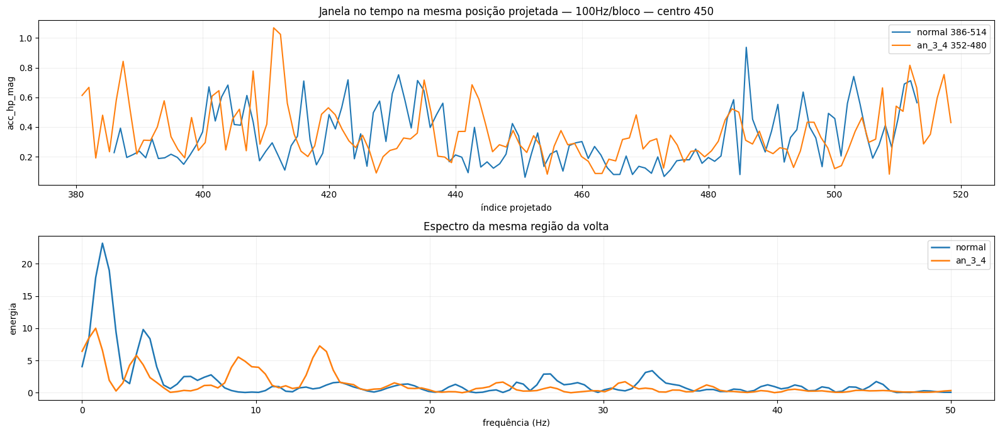

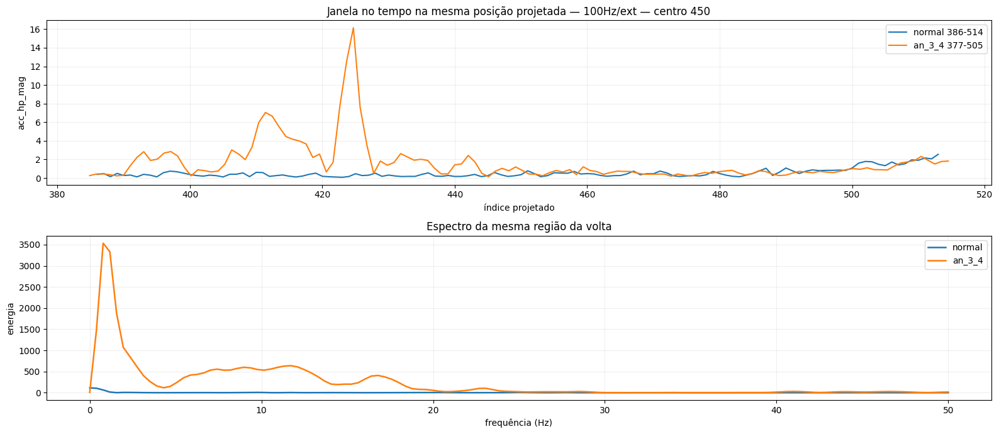

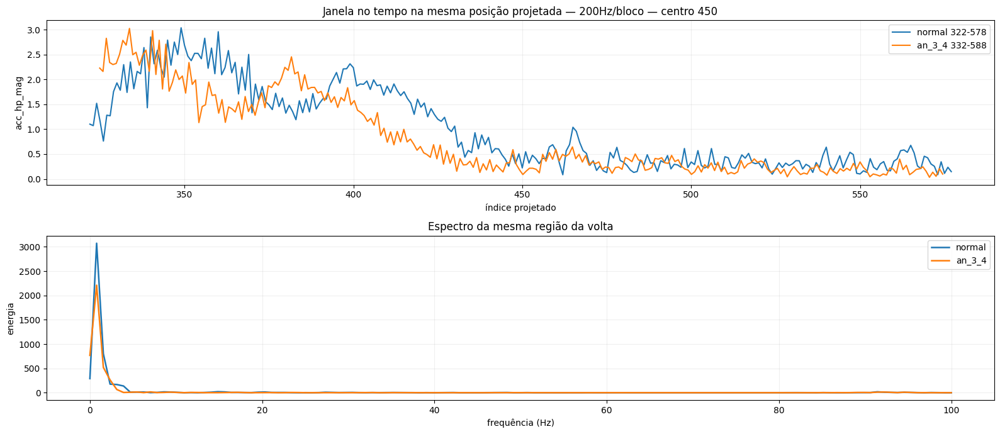

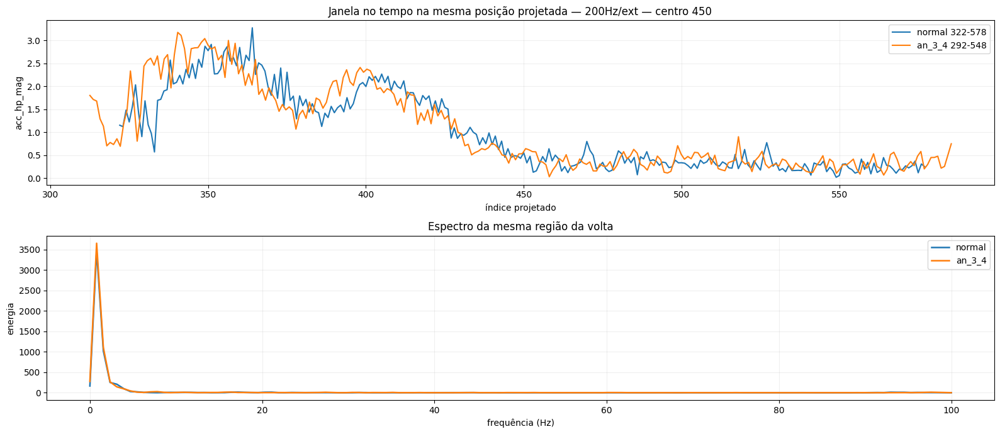

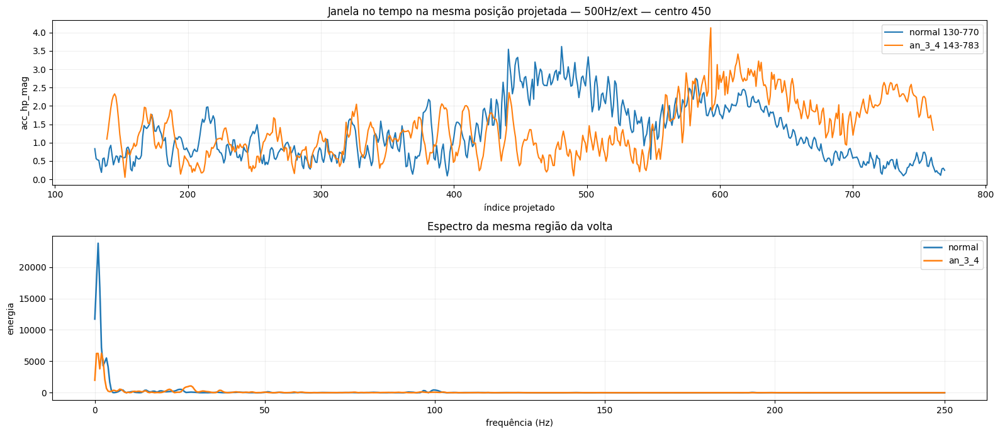

In [41]:
for freq_label in resultados:
    for tipo in resultados[freq_label]:
        if 'an_3_4' in dados[freq_label][tipo] and len(dados[freq_label][tipo]['an_3_4']['dfs']) > 0:
            comparar_janelas_mesma_posicao(freq_label=freq_label, tipo=tipo, nome_grupo='an_3_4', centro=450, col='acc_hp_mag')

## Exportação
Função só foi definida mas não chamada

In [44]:
def salvar_modelo_e_resultados(diretorio_saida='.', resultados_percentis=None):
    """
    Exporta modelos, resultados e métricas sem executar automaticamente o salvamento.
    
    Opcionalmente inclui a varredura de percentis e retorna os caminhos dos arquivos criados.
    """
    pacote_modelo = {
        'modelos': modelos,
        'resultados': resultados,
        'metricas': metricas,
        'resultados_percentis': resultados_percentis,
        'raiz_dados': RAIZ_DADOS,
        'frequencias': FREQUENCIAS,
        'tipos_coleta': TIPOS_COLETA,
        'grupos_anomalia': GRUPOS_ANOMALIA,
        'feature_cols': FEATURE_COLS,
        'freq_bands_base': FREQ_BANDS_BASE,
        'usar_dtw': USAR_DTW,
        'min_janelas_consecutivas': MIN_JANELAS_CONSECUTIVAS,
        'min_comprimento_intervalo_seg': MIN_COMPRIMENTO_INTERVALO_SEG,
        'score_min_intervalo': SCORE_MIN_INTERVALO,
    }

    caminho_modelo = os.path.join(
        diretorio_saida,
        'modelo_freq_variadas_madgwick_dtw_posicao_limiar_local.pkl'
    )
    joblib.dump(pacote_modelo, caminho_modelo)

    resumo_total = []
    for freq_label in resultados:
        for tipo in resultados[freq_label]:
            resumo_total.append(resultados[freq_label][tipo]['resumo_arquivos'])
    resumo_total = pd.concat(resumo_total, ignore_index=True)
    caminho_resumo = os.path.join(diretorio_saida, 'resumo_deteccoes_freq_variadas.csv')
    resumo_total.to_csv(caminho_resumo, index=False)

    metricas_total = []
    for freq_label in metricas:
        for tipo in metricas[freq_label]:
            dfm = metricas[freq_label][tipo].copy()
            dfm.insert(0, 'tipo', tipo)
            dfm.insert(0, 'freq', freq_label)
            metricas_total.append(dfm)
    metricas_total = pd.concat(metricas_total, ignore_index=True)
    caminho_metricas = os.path.join(diretorio_saida, 'metricas_deteccoes_freq_variadas.csv')
    metricas_total.to_csv(caminho_metricas, index=False)

    caminhos = [caminho_modelo, caminho_resumo, caminho_metricas]

    if resultados_percentis is not None:
        caminho_percentis = os.path.join(diretorio_saida, 'varredura_percentis_freq_variadas.csv')
        resultados_percentis.to_csv(caminho_percentis, index=False)
        caminhos.append(caminho_percentis)

    return caminhos